In [ ]:

import os

print("Files available in /content:\n")

for file in os.listdir('/content'):
    print(file)


Files available in /content:

.config
online+retail.zip
drive
sample_data


In [ ]:

import zipfile
import os
import glob

# Find ZIP files in /content
zip_files = glob.glob('/content/online+retail.zip')

print("ZIP files found:", zip_files)

# Extract the first ZIP file
if zip_files:
    zip_path = zip_files[0]

    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('/content/retail_data')

    print("\nExtraction successful!")
    print("Extracted files:", os.listdir('/content/retail_data'))

else:
    print("No ZIP file found. Please upload the dataset again.")


ZIP files found: ['/content/online+retail.zip']

Extraction successful!
Extracted files: ['Online Retail.xlsx']


In [ ]:

import pandas as pd
import numpy as np

# Load the extracted Excel dataset
df = pd.read_excel('/content/retail_data/Online Retail.xlsx')

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display first 5 records
display(df.head())


Dataset loaded successfully!
Number of rows: 541909
Number of columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:

# Dataset information
print("DATASET INFORMATION")
df.info()

# Statistical summary
print("\nSTATISTICAL SUMMARY")
display(df.describe(include='all'))

# Missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Duplicate records
print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

STATISTICAL SUMMARY


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909.0,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900.0,4070,4223,NaN,NaN,NaN,NaN,38
top,573585.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1114.0,2313,2369,NaN,NaN,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570,NaN
min,NaN,NaN,NaN,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,2011-03-28 11:34:00,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,2011-07-19 17:17:00,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,2011-10-19 11:27:00,4.130000,16791.000000,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,NaN



MISSING VALUES
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

DUPLICATE RECORDS
5268


## 1. Initial Data Exploration and Data Quality Assessment

The Online Retail dataset contains 541,909 transaction records and 8 attributes. The dataset was initially inspected using Pandas to understand its structure, data types, statistical properties and data quality.

The initial inspection identified missing values in the Description and CustomerID columns, along with duplicate records. Numerical analysis also revealed unusually high and negative values in the Quantity and UnitPrice columns.

These observations indicate that the raw dataset requires further cleaning and preprocessing before it can be used for customer segmentation.

In [ ]:

# ==========================================
# DETAILED DATA QUALITY ASSESSMENT
# ==========================================

# 1. Missing value analysis
missing_values = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

print("MISSING VALUE ANALYSIS")
display(missing_values)


# 2. Duplicate record analysis
print("\nDUPLICATE RECORD ANALYSIS")
print("Total duplicate records:", df.duplicated().sum())


# 3. Negative quantity analysis
negative_quantity = (df['Quantity'] < 0).sum()
zero_quantity = (df['Quantity'] == 0).sum()

print("\nQUANTITY ANALYSIS")
print("Negative quantities:", negative_quantity)
print("Zero quantities:", zero_quantity)


# 4. Unit price analysis
negative_price = (df['UnitPrice'] < 0).sum()
zero_price = (df['UnitPrice'] == 0).sum()

print("\nUNIT PRICE ANALYSIS")
print("Negative prices:", negative_price)
print("Zero prices:", zero_price)


# 5. Cancellation invoice analysis
cancelled_invoices = df['InvoiceNo'].astype(str).str.startswith('C')

print("\nCANCELLATION ANALYSIS")
print("Cancellation records:", cancelled_invoices.sum())


# 6. Unique values
print("\nUNIQUE VALUE ANALYSIS")
print("Unique invoices:", df['InvoiceNo'].nunique())
print("Unique products:", df['StockCode'].nunique())
print("Unique customers:", df['CustomerID'].nunique())
print("Unique countries:", df['Country'].nunique())


MISSING VALUE ANALYSIS


,Missing Count,Missing Percentage
InvoiceNo,0,0.000000
StockCode,0,0.000000
Description,1454,0.268311
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
CustomerID,135080,24.926694
Country,0,0.000000



DUPLICATE RECORD ANALYSIS
Total duplicate records: 5268

QUANTITY ANALYSIS
Negative quantities: 10624
Zero quantities: 0

UNIT PRICE ANALYSIS
Negative prices: 2
Zero prices: 2515

CANCELLATION ANALYSIS
Cancellation records: 9288

UNIQUE VALUE ANALYSIS
Unique invoices: 25900
Unique products: 4070
Unique customers: 4372
Unique countries: 38


## 2. Investigation of Unusual and Inconsistent Records

The initial data-quality assessment revealed negative quantities, cancellation invoices, zero-priced transactions and duplicate records.

These records require further investigation to distinguish genuine business activities from incorrect or inconsistent data. Therefore, representative records will be examined before applying cleaning operations.

In [ ]:

# Preserve the original dataset
df_raw = df.copy(deep=True)

# Identify different types of unusual records
cancellation_mask = df_raw['InvoiceNo'].astype(str).str.startswith('C')
negative_quantity_mask = df_raw['Quantity'] < 0
zero_price_mask = df_raw['UnitPrice'] == 0
negative_price_mask = df_raw['UnitPrice'] < 0
duplicate_mask = df_raw.duplicated()

# 1. Check overlap between cancellations and negative quantities
print("CANCELLATION AND RETURN ANALYSIS")

print("Cancellation records:", cancellation_mask.sum())

print("Negative quantity records:",
      negative_quantity_mask.sum())

print("Both cancellation and negative quantity:",
      (cancellation_mask & negative_quantity_mask).sum())

print("\nNegative quantities without cancellation:",
      (~cancellation_mask & negative_quantity_mask).sum())


# 2. Display sample cancellation records
print("\nSAMPLE CANCELLATION RECORDS")
display(df_raw[cancellation_mask].head(10))


# 3. Display sample negative quantity records
print("\nSAMPLE NEGATIVE QUANTITY RECORDS")
display(df_raw[negative_quantity_mask].head(10))


# 4. Display zero-price records
print("\nSAMPLE ZERO PRICE RECORDS")
display(df_raw[zero_price_mask].head(10))


# 5. Display negative-price records
print("\nNEGATIVE PRICE RECORDS")
display(df_raw[negative_price_mask])


# 6. Display duplicate records
print("\nSAMPLE DUPLICATE RECORDS")
display(df_raw[duplicate_mask].head(10))


CANCELLATION AND RETURN ANALYSIS
Cancellation records: 9288
Negative quantity records: 10624
Both cancellation and negative quantity: 9288

Negative quantities without cancellation: 1336

SAMPLE CANCELLATION RECORDS


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom



SAMPLE NEGATIVE QUANTITY RECORDS


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom



SAMPLE ZERO PRICE RECORDS


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom



NEGATIVE PRICE RECORDS


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom



SAMPLE DUPLICATE RECORDS


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
587,536412,22273,FELTCRAFT DOLL MOLLY,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
589,536412,22749,FELTCRAFT PRINCESS CHARLOTTE DOLL,1,2010-12-01 11:49:00,3.75,17920.0,United Kingdom
594,536412,22141,CHRISTMAS CRAFT TREE TOP ANGEL,1,2010-12-01 11:49:00,2.10,17920.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
600,536412,22569,FELTCRAFT CUSHION BUTTERFLY,2,2010-12-01 11:49:00,3.75,17920.0,United Kingdom


## 3. Data Cleaning and Preprocessing

### 3.1 Duplicate Record Removal

Duplicate records can affect statistical analysis and lead to incorrect transaction counts. The dataset was checked for exact duplicate rows using Pandas' `duplicated()` function.

All exact duplicate records were removed using `drop_duplicates()`. The original dataset was preserved to allow comparison between the raw and cleaned data.

In [ ]:

# Create a working copy of the original dataset
df_cleaned = df_raw.copy()

# Count duplicates before removal
duplicates_before = df_cleaned.duplicated().sum()

print("Duplicates before cleaning:", duplicates_before)

# Remove exact duplicate records
df_cleaned = df_cleaned.drop_duplicates()

# Check duplicates after removal
duplicates_after = df_cleaned.duplicated().sum()

print("Duplicates after cleaning:", duplicates_after)

# Compare dataset dimensions
print("\nOriginal dataset shape:", df_raw.shape)
print("Cleaned dataset shape:", df_cleaned.shape)

print("\nRecords removed:", len(df_raw) - len(df_cleaned))


Duplicates before cleaning: 5268
Duplicates after cleaning: 0

Original dataset shape: (541909, 8)
Cleaned dataset shape: (536641, 8)

Records removed: 5268


In [ ]:

# Identify cancellation invoices
cancellation_mask = (
    df_cleaned['InvoiceNo']
    .astype(str)
    .str.startswith('C')
)

# Separate cancellation transactions
df_cancellations = df_cleaned[cancellation_mask].copy()

# Separate non-cancellation transactions
df_non_cancelled = df_cleaned[~cancellation_mask].copy()

# Identify negative quantity records in non-cancelled invoices
returns_mask = df_non_cancelled['Quantity'] < 0

df_returns = df_non_cancelled[returns_mask].copy()

# Separate positive quantity transactions
df_positive = df_non_cancelled[
    df_non_cancelled['Quantity'] > 0
].copy()

print("TRANSACTION SEPARATION RESULTS")

print("Cancellation records:", len(df_cancellations))
print("Negative quantity records without cancellation:",
      len(df_returns))
print("Positive quantity records:", len(df_positive))

print("\nTotal records after duplicate removal:",
      len(df_cleaned))


TRANSACTION SEPARATION RESULTS
Cancellation records: 9251
Negative quantity records without cancellation: 1336
Positive quantity records: 526054

Total records after duplicate removal: 536641


In [ ]:

# Find records with missing descriptions
missing_desc = df_cleaned[
    df_cleaned['Description'].isnull()
]

print("Records with missing descriptions:",
      len(missing_desc))

# Check how many missing descriptions have known StockCodes
known_stockcodes = set(
    df_cleaned.loc[
        df_cleaned['Description'].notnull(),
        'StockCode'
    ]
)

recoverable = missing_desc[
    missing_desc['StockCode'].isin(known_stockcodes)
]

print("Missing descriptions with StockCodes found elsewhere:",
      len(recoverable))

# Display sample missing descriptions
display(missing_desc.head(15))


Records with missing descriptions: 1454
Missing descriptions with StockCodes found elsewhere: 1342


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


### 3.2 Handling Missing Product Descriptions

The dataset initially contained 1,454 missing values in the Description column. An investigation revealed that 1,342 of these records had StockCodes that appeared in other records with available descriptions.

The StockCode attribute was used to investigate whether missing product descriptions could be recovered from existing records. Before imputation, the consistency of the StockCode-to-Description mapping was verified to avoid assigning incorrect product names.

In [ ]:

# Identify unique product descriptions for each StockCode
stock_description_mapping = (
    df_cleaned[df_cleaned['Description'].notna()]
    .groupby('StockCode')['Description']
    .nunique()
)

# Find StockCodes with exactly one description
unambiguous_codes = stock_description_mapping[
    stock_description_mapping == 1
].index

# Find StockCodes with multiple descriptions
ambiguous_codes = stock_description_mapping[
    stock_description_mapping > 1
].index

print("StockCodes with one unique description:",
      len(unambiguous_codes))

print("StockCodes with multiple descriptions:",
      len(ambiguous_codes))

# Check missing descriptions that can safely be recovered
recoverable_records = df_cleaned[
    df_cleaned['Description'].isnull() &
    df_cleaned['StockCode'].isin(unambiguous_codes)
]

print("\nSafely recoverable records:",
      len(recoverable_records))

print("Missing descriptions requiring further investigation:",
      df_cleaned['Description'].isnull().sum()
      - len(recoverable_records))


StockCodes with one unique description: 3308
StockCodes with multiple descriptions: 650

Safely recoverable records: 1033
Missing descriptions requiring further investigation: 421


In [ ]:

# Create a mapping using only unambiguous StockCodes
description_mapping = (
    df_cleaned[
        df_cleaned['Description'].notna() &
        df_cleaned['StockCode'].isin(unambiguous_codes)
    ]
    .drop_duplicates(subset='StockCode')
    .set_index('StockCode')['Description']
)

# Count missing descriptions before imputation
missing_before = df_cleaned['Description'].isnull().sum()

# Fill missing descriptions using StockCode
df_cleaned['Description'] = df_cleaned['Description'].fillna(
    df_cleaned['StockCode'].map(description_mapping)
)

# Count missing descriptions after imputation
missing_after = df_cleaned['Description'].isnull().sum()

print("Missing descriptions before:", missing_before)
print("Descriptions recovered:",
      missing_before - missing_after)
print("Missing descriptions remaining:", missing_after)


Missing descriptions before: 1454
Descriptions recovered: 1033
Missing descriptions remaining: 421


In [ ]:

print("DESCRIPTION CLEANING SUMMARY")

print("Total records:", len(df_cleaned))

print("Missing descriptions:",
      df_cleaned['Description'].isnull().sum())

print("\nMissing values in all columns:")
display(df_cleaned.isnull().sum())


DESCRIPTION CLEANING SUMMARY
Total records: 536641
Missing descriptions: 421

Missing values in all columns:


,0
InvoiceNo,0
StockCode,0
Description,421
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135037
Country,0


**Observation:**

Out of 1,454 missing product descriptions, 1,033 descriptions were successfully recovered using the StockCode attribute after verifying the uniqueness of product descriptions. The remaining 421 values could not be reliably recovered and were retained as missing values.

This reduced the missing product descriptions by approximately 71.04% without introducing fabricated product information.

### 3.3 Handling Missing Customer Identification Values

The CustomerID column contains 135,037 missing values after duplicate removal and description recovery. Since CustomerID represents a unique customer identifier, numerical imputation would introduce incorrect customer identities.

Therefore, records with missing CustomerIDs will be retained in the general transaction dataset but excluded from customer-level segmentation and RFM calculations.

In [ ]:

# Investigate missing CustomerIDs

missing_customer = df_cleaned[
    df_cleaned['CustomerID'].isnull()
]

available_customer = df_cleaned[
    df_cleaned['CustomerID'].notnull()
]

print("CUSTOMER ID ANALYSIS")

print("Total records:", len(df_cleaned))

print("Missing CustomerIDs:",
      len(missing_customer))

print("Available CustomerIDs:",
      len(available_customer))

print("\nMissing CustomerID percentage:",
      round(
          missing_customer.shape[0] / len(df_cleaned) * 100,
          2
      ), "%")


# Compare missing CustomerIDs with transaction types

print("\nMISSING CUSTOMERID TRANSACTION ANALYSIS")

print("Cancellation records:",
      missing_customer['InvoiceNo'].astype(str)
      .str.startswith('C').sum())

print("Negative quantity records:",
      (missing_customer['Quantity'] < 0).sum())

print("Zero-price records:",
      (missing_customer['UnitPrice'] == 0).sum())

print("Positive quantity records:",
      (missing_customer['Quantity'] > 0).sum())


# Display sample records
print("\nSAMPLE RECORDS WITH MISSING CUSTOMERID")
display(missing_customer.head(10))


CUSTOMER ID ANALYSIS
Total records: 536641
Missing CustomerIDs: 135037
Available CustomerIDs: 401604

Missing CustomerID percentage: 25.16 %

MISSING CUSTOMERID TRANSACTION ANALYSIS
Cancellation records: 379
Negative quantity records: 1715
Zero-price records: 2470
Positive quantity records: 133322

SAMPLE RECORDS WITH MISSING CUSTOMERID


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom
1447,536544,21790,VINTAGE SNAP CARDS,9,2010-12-01 14:32:00,1.66,NaN,United Kingdom
1448,536544,21791,VINTAGE HEADS AND TAILS CARD GAME,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1449,536544,21801,CHRISTMAS TREE DECORATION WITH BELL,10,2010-12-01 14:32:00,0.43,NaN,United Kingdom
1450,536544,21802,CHRISTMAS TREE HEART DECORATION,9,2010-12-01 14:32:00,0.43,NaN,United Kingdom
1451,536544,21803,CHRISTMAS TREE STAR DECORATION,11,2010-12-01 14:32:00,0.43,NaN,United Kingdom


### 3.3 Handling Missing CustomerID Values

The dataset contains 135,037 missing CustomerID values, representing approximately 25.16% of the records after duplicate removal.

Since CustomerID is an identifier, numerical imputation would create artificial customer identities and negatively affect customer-level analysis.

Therefore, missing CustomerID values were retained in the general cleaned transaction dataset. Records with available CustomerIDs will be used for customer segmentation, while unidentified transactions will remain available for general transaction-level analysis.

This approach prevents unnecessary data loss and avoids introducing fabricated customer information.

In [ ]:

# Create separate datasets

# Records with identifiable customers
df_customer = df_cleaned[
    df_cleaned['CustomerID'].notna()
].copy()

# Records without identifiable customers
df_unknown_customer = df_cleaned[
    df_cleaned['CustomerID'].isna()
].copy()

print("CUSTOMER DATA SEPARATION")

print("Original cleaned records:", len(df_cleaned))

print("Identifiable customer records:", len(df_customer))

print("Unidentified customer records:",
      len(df_unknown_customer))

print("\nVerification:",
      len(df_customer) + len(df_unknown_customer)
      == len(df_cleaned))


CUSTOMER DATA SEPARATION
Original cleaned records: 536641
Identifiable customer records: 401604
Unidentified customer records: 135037

Verification: True


### 3.4 Investigation of Invalid and Unusual Unit Prices

The UnitPrice column contains zero-priced and negative-priced records. These values require investigation because they may represent free promotional items, adjustments or invalid transactions.

The records will be examined using their product descriptions, invoice numbers and quantities before deciding whether they should be excluded from the sales analysis.

In [ ]:

# Analyze zero-priced records
zero_price_records = df_cleaned[
    df_cleaned['UnitPrice'] == 0
].copy()

print("ZERO PRICE ANALYSIS")

print("Total zero-price records:",
      len(zero_price_records))

print("\nMost common descriptions:")
display(
    zero_price_records['Description']
    .value_counts(dropna=False)
    .head(15)
)


# Analyze negative-priced records
negative_price_records = df_cleaned[
    df_cleaned['UnitPrice'] < 0
].copy()

print("\nNEGATIVE PRICE ANALYSIS")

display(negative_price_records)


# Check invoice types
print("\nZERO PRICE INVOICE ANALYSIS")

print(
    zero_price_records['InvoiceNo']
    .astype(str)
    .str.startswith('C')
    .value_counts()
)


# Calculate transaction values
zero_price_records['TransactionValue'] = (
    zero_price_records['Quantity'] *
    zero_price_records['UnitPrice']
)

print("\nZero-price transaction value:")
print(zero_price_records['TransactionValue'].sum())


ZERO PRICE ANALYSIS
Total zero-price records: 2510

Most common descriptions:


,count
Description,
NaN,421
check,159
?,47
damages,45
damaged,43
found,25
sold as set on dotcom,20
adjustment,16
Damaged,14



NEGATIVE PRICE ANALYSIS


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom



ZERO PRICE INVOICE ANALYSIS
InvoiceNo
False    2510
Name: count, dtype: int64

Zero-price transaction value:
0.0


In [ ]:
# Recalculate transaction categories using the cleaned dataset

# 1. Cancellation transactions
cancellation_mask = (
    df_cleaned['InvoiceNo']
    .astype(str)
    .str.startswith('C')
)

df_cancellations = df_cleaned[cancellation_mask].copy()

# 2. Non-cancellation transactions
df_non_cancelled = df_cleaned[~cancellation_mask].copy()

# 3. Negative quantity transactions (returns/reversals)
returns_mask = df_non_cancelled['Quantity'] < 0

df_returns = df_non_cancelled[returns_mask].copy()

# 4. Zero-price transactions
df_zero_price = df_cleaned[
    df_cleaned['UnitPrice'] == 0
].copy()

# 5. Negative-price accounting adjustments
df_negative_price = df_cleaned[
    df_cleaned['UnitPrice'] < 0
].copy()

# 6. Normal positive-quantity, positive-price transactions
df_regular_sales = df_cleaned[
    (~cancellation_mask) &
    (df_cleaned['Quantity'] > 0) &
    (df_cleaned['UnitPrice'] > 0)
].copy()

# Display the results
print("TRANSACTION CATEGORY SUMMARY")
print("--------------------------------")
print("Total cleaned records:", len(df_cleaned))
print("Cancellation records:", len(df_cancellations))
print("Negative quantity records:", len(df_returns))
print("Zero-price records:", len(df_zero_price))
print("Negative-price records:", len(df_negative_price))
print("Regular positive sales records:", len(df_regular_sales))

TRANSACTION CATEGORY SUMMARY
--------------------------------
Total cleaned records: 536641
Cancellation records: 9251
Negative quantity records: 1336
Zero-price records: 2510
Negative-price records: 2
Regular positive sales records: 524878


In [ ]:
# Basic statistical analysis of regular sales

print("QUANTITY STATISTICS")
display(df_regular_sales['Quantity'].describe())

print("\nUNIT PRICE STATISTICS")
display(df_regular_sales['UnitPrice'].describe())

# Calculate total transaction value
df_regular_sales['TotalPrice'] = (
    df_regular_sales['Quantity'] *
    df_regular_sales['UnitPrice']
)

print("\nTRANSACTION VALUE STATISTICS")
display(df_regular_sales['TotalPrice'].describe())

QUANTITY STATISTICS


,Quantity
count,524878.000000
mean,10.616600
std,156.280031
min,1.000000
25%,1.000000
50%,4.000000
75%,11.000000
max,80995.000000



UNIT PRICE STATISTICS


,UnitPrice
count,524878.000000
mean,3.922573
std,36.093028
min,0.001000
25%,1.250000
50%,2.080000
75%,4.130000
max,13541.330000



TRANSACTION VALUE STATISTICS


,TotalPrice
count,524878.000000
mean,20.275399
std,271.693566
min,0.001000
25%,3.900000
50%,9.920000
75%,17.700000
max,168469.600000


In [ ]:
# Identify extreme values

print("TOP 10 QUANTITIES")
display(
    df_regular_sales.nlargest(10, 'Quantity')[
        ['InvoiceNo', 'StockCode', 'Description',
         'Quantity', 'UnitPrice', 'Country']
    ]
)

print("\nTOP 10 UNIT PRICES")
display(
    df_regular_sales.nlargest(10, 'UnitPrice')[
        ['InvoiceNo', 'StockCode', 'Description',
         'Quantity', 'UnitPrice', 'Country']
    ]
)

print("\nTOP 10 TRANSACTION VALUES")
display(
    df_regular_sales.nlargest(10, 'TotalPrice')[
        ['InvoiceNo', 'StockCode', 'Description',
         'Quantity', 'UnitPrice', 'TotalPrice', 'Country']
    ]
)

TOP 10 QUANTITIES


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,United Kingdom
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,United Kingdom
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,United Kingdom
206121,554868,22197,SMALL POPCORN HOLDER,4300,0.72,United Kingdom
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82,United Kingdom
270885,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,United Kingdom
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,United Kingdom
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,United Kingdom
433788,573995,16014,SMALL CHINESE STYLE SCISSOR,3000,0.32,United Kingdom
4945,536830,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,0.18,United Kingdom



TOP 10 UNIT PRICES


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Country
15017,537632,AMAZONFEE,AMAZON FEE,1,13541.33,United Kingdom
299982,A563185,B,Adjust bad debt,1,11062.06,United Kingdom
173382,551697,POST,POSTAGE,1,8142.75,United Kingdom
297723,562955,DOT,DOTCOM POSTAGE,1,4505.17,United Kingdom
268028,560373,M,Manual,1,4287.63,United Kingdom
422351,573077,M,Manual,1,4161.06,France
422376,573080,M,Manual,1,4161.06,France
406406,571751,M,Manual,1,3949.32,Singapore
374542,569382,M,Manual,1,3155.95,United Kingdom
347948,567353,M,Manual,1,2653.95,Hong Kong



TOP 10 TRANSACTION VALUES


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,TotalPrice,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,United Kingdom
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,United Kingdom
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,United Kingdom
15017,537632,AMAZONFEE,AMAZON FEE,1,13541.33,13541.33,United Kingdom
299982,A563185,B,Adjust bad debt,1,11062.06,11062.06,United Kingdom
173382,551697,POST,POSTAGE,1,8142.75,8142.75,United Kingdom
348325,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72,United Kingdom
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,United Kingdom
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,United Kingdom
421601,573003,23084,RABBIT NIGHT LIGHT,2400,2.08,4992.00,Netherlands


In [ ]:
# IQR-based outlier detection

def detect_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_limit) |
        (data[column] > upper_limit)
    ]

    print(f"\nOUTLIER ANALYSIS: {column}")
    print("--------------------------------")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Number of outliers:", len(outliers))
    print("Percentage of outliers:",
          round(len(outliers) / len(data) * 100, 2), "%")

    return outliers


quantity_outliers = detect_outliers(
    df_regular_sales, 'Quantity'
)

price_outliers = detect_outliers(
    df_regular_sales, 'UnitPrice'
)

value_outliers = detect_outliers(
    df_regular_sales, 'TotalPrice'
)


OUTLIER ANALYSIS: Quantity
--------------------------------
Q1: 1.0
Q3: 11.0
IQR: 10.0
Lower limit: -14.0
Upper limit: 26.0
Number of outliers: 27111
Percentage of outliers: 5.17 %

OUTLIER ANALYSIS: UnitPrice
--------------------------------
Q1: 1.25
Q3: 4.13
IQR: 2.88
Lower limit: -3.0700000000000003
Upper limit: 8.45
Number of outliers: 37827
Percentage of outliers: 7.21 %

OUTLIER ANALYSIS: TotalPrice
--------------------------------
Q1: 3.9
Q3: 17.700000000000003
IQR: 13.800000000000002
Lower limit: -16.800000000000004
Upper limit: 38.400000000000006
Number of outliers: 42624
Percentage of outliers: 8.12 %


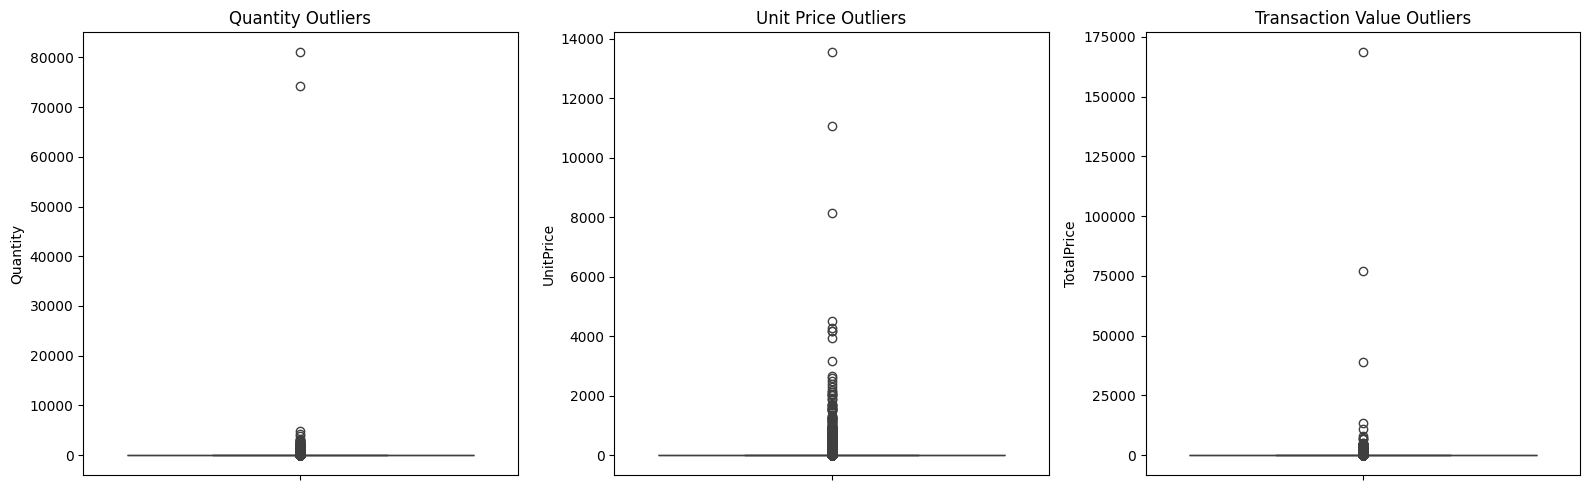

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(y=df_regular_sales['Quantity'], ax=axes[0])
axes[0].set_title('Quantity Outliers')

sns.boxplot(y=df_regular_sales['UnitPrice'], ax=axes[1])
axes[1].set_title('Unit Price Outliers')

sns.boxplot(y=df_regular_sales['TotalPrice'], ax=axes[2])
axes[2].set_title('Transaction Value Outliers')

plt.tight_layout()
plt.show()

In [ ]:
# Inspect the 25 highest-priced entries
print("TOP 25 UNIT PRICE RECORDS")

display(
    df_regular_sales.nlargest(25, 'UnitPrice')[
        ['InvoiceNo', 'StockCode', 'Description',
         'Quantity', 'UnitPrice', 'TotalPrice',
         'CustomerID', 'Country']
    ]
)

# Identify frequently occurring non-standard descriptions
print("\nMOST COMMON HIGH-PRICE DESCRIPTIONS")

display(
    price_outliers['Description']
    .value_counts(dropna=False)
    .head(20)
)

# Inspect the 25 highest-quantity transactions
print("\nTOP 25 QUANTITY RECORDS")

display(
    df_regular_sales.nlargest(25, 'Quantity')[
        ['InvoiceNo', 'StockCode', 'Description',
         'Quantity', 'UnitPrice', 'TotalPrice',
         'CustomerID', 'Country']
    ]
)

TOP 25 UNIT PRICE RECORDS


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,TotalPrice,CustomerID,Country
15017,537632,AMAZONFEE,AMAZON FEE,1,13541.33,13541.33,NaN,United Kingdom
299982,A563185,B,Adjust bad debt,1,11062.06,11062.06,NaN,United Kingdom
173382,551697,POST,POSTAGE,1,8142.75,8142.75,16029.0,United Kingdom
297723,562955,DOT,DOTCOM POSTAGE,1,4505.17,4505.17,NaN,United Kingdom
268028,560373,M,Manual,1,4287.63,4287.63,NaN,United Kingdom
422351,573077,M,Manual,1,4161.06,4161.06,12536.0,France
422376,573080,M,Manual,1,4161.06,4161.06,12536.0,France
406406,571751,M,Manual,1,3949.32,3949.32,12744.0,Singapore
374542,569382,M,Manual,1,3155.95,3155.95,15502.0,United Kingdom
347948,567353,M,Manual,1,2653.95,2653.95,NaN,Hong Kong



MOST COMMON HIGH-PRICE DESCRIPTIONS


,count
Description,
REGENCY CAKESTAND 3 TIER,2004
POSTAGE,1091
DOTCOM POSTAGE,697
IVORY KITCHEN SCALES,677
RED RETROSPOT CAKE STAND,531
CREAM SWEETHEART MINI CHEST,523
RED KITCHEN SCALES,509
VINTAGE UNION JACK BUNTING,478
ENAMEL BREAD BIN CREAM,453



TOP 25 QUANTITY RECORDS


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,TotalPrice,CustomerID,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,16446.0,United Kingdom
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,12346.0,United Kingdom
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,1008.00,12901.0,United Kingdom
206121,554868,22197,SMALL POPCORN HOLDER,4300,0.72,3096.00,13135.0,United Kingdom
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,0.82,3202.92,18087.0,United Kingdom
270885,560599,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,191.16,14609.0,United Kingdom
52711,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,15749.0,United Kingdom
160546,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,15749.0,United Kingdom
433788,573995,16014,SMALL CHINESE STYLE SCISSOR,3000,0.32,960.00,16308.0,United Kingdom
4945,536830,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,0.18,518.40,16754.0,United Kingdom


In [ ]:
# Identify non-product transaction descriptions

non_product_descriptions = [
    'AMAZON FEE',
    'POSTAGE',
    'DOTCOM POSTAGE',
    'Adjust bad debt',
    'Manual'
]

# Separate non-product charges
df_non_product = df_regular_sales[
    df_regular_sales['Description'].str.strip().str.upper().isin(
        [x.upper() for x in non_product_descriptions]
    )
].copy()

# Create a product-only transaction dataset
df_product_sales = df_regular_sales[
    ~df_regular_sales['Description'].str.strip().str.upper().isin(
        [x.upper() for x in non_product_descriptions]
    )
].copy()

print("NON-PRODUCT TRANSACTION ANALYSIS")
print("--------------------------------")
print("Non-product records:", len(df_non_product))
print("Product sales records:", len(df_product_sales))
print("Original regular sales records:", len(df_regular_sales))

print("\nNon-product descriptions:")
display(df_non_product['Description'].value_counts())

NON-PRODUCT TRANSACTION ANALYSIS
--------------------------------
Non-product records: 2152
Product sales records: 522726
Original regular sales records: 524878

Non-product descriptions:


,count
Description,
POSTAGE,1126
DOTCOM POSTAGE,706
Manual,317
AMAZON FEE,2
Adjust bad debt,1


In [ ]:
# Check the resulting product sales dataset

print("PRODUCT SALES DATASET")
print("----------------------")

print("Shape:", df_product_sales.shape)

print("\nMissing values:")
display(df_product_sales.isnull().sum())

print("\nStatistical summary:")
display(
    df_product_sales[
        ['Quantity', 'UnitPrice', 'TotalPrice']
    ].describe()
)

PRODUCT SALES DATASET
----------------------
Shape: (522726, 9)

Missing values:


,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,131428
Country,0
TotalPrice,0



Statistical summary:


,Quantity,UnitPrice,TotalPrice
count,522726.000000,522726.000000,522726.000000
mean,10.639563,3.287968,19.618661
std,156.566366,4.465101,269.890586
min,1.000000,0.001000,0.001000
25%,1.000000,1.250000,3.900000
50%,4.000000,2.080000,9.900000
75%,12.000000,4.130000,17.700000
max,80995.000000,649.500000,168469.600000


In [ ]:
# Create a separate copy for transformation
df_transformed = df_product_sales.copy()

# Apply logarithmic transformation
df_transformed['Log_Quantity'] = np.log1p(
    df_transformed['Quantity']
)

df_transformed['Log_UnitPrice'] = np.log1p(
    df_transformed['UnitPrice']
)

df_transformed['Log_TotalPrice'] = np.log1p(
    df_transformed['TotalPrice']
)

print("TRANSFORMED DATASET")
print("-------------------")

display(
    df_transformed[
        ['Quantity', 'Log_Quantity',
         'UnitPrice', 'Log_UnitPrice',
         'TotalPrice', 'Log_TotalPrice']
    ].head()
)

TRANSFORMED DATASET
-------------------


,Quantity,Log_Quantity,UnitPrice,Log_UnitPrice,TotalPrice,Log_TotalPrice
0,6,1.945910,2.55,1.266948,15.30,2.791165
1,6,1.945910,3.39,1.479329,20.34,3.060583
2,8,2.197225,2.75,1.321756,22.00,3.135494
3,6,1.945910,3.39,1.479329,20.34,3.060583
4,6,1.945910,3.39,1.479329,20.34,3.060583


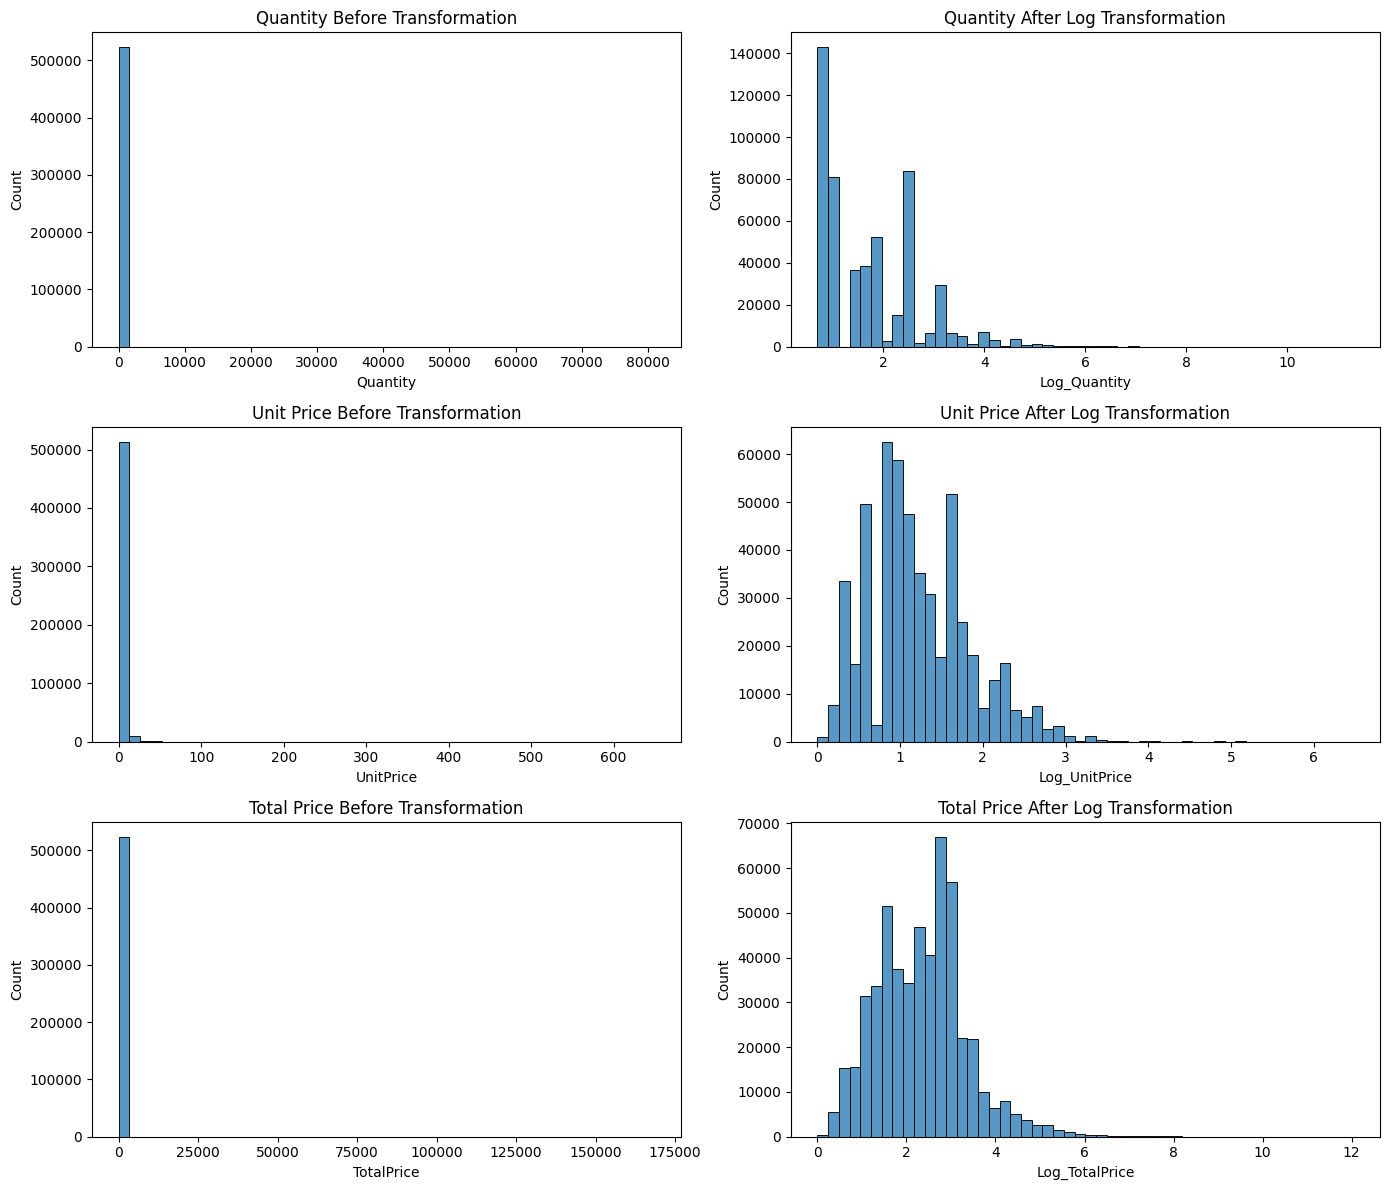

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

# Quantity
sns.histplot(
    df_transformed['Quantity'],
    bins=50,
    ax=axes[0, 0]
)
axes[0, 0].set_title('Quantity Before Transformation')

sns.histplot(
    df_transformed['Log_Quantity'],
    bins=50,
    ax=axes[0, 1]
)
axes[0, 1].set_title('Quantity After Log Transformation')

# Unit Price
sns.histplot(
    df_transformed['UnitPrice'],
    bins=50,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Unit Price Before Transformation')

sns.histplot(
    df_transformed['Log_UnitPrice'],
    bins=50,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Unit Price After Log Transformation')

# Total Price
sns.histplot(
    df_transformed['TotalPrice'],
    bins=50,
    ax=axes[2, 0]
)
axes[2, 0].set_title('Total Price Before Transformation')

sns.histplot(
    df_transformed['Log_TotalPrice'],
    bins=50,
    ax=axes[2, 1]
)
axes[2, 1].set_title('Total Price After Log Transformation')

plt.tight_layout()
plt.show()

In [ ]:
# Compare skewness before and after log transformation

skewness_comparison = pd.DataFrame({
    'Feature': ['Quantity', 'UnitPrice', 'TotalPrice'],

    'Before Transformation': [
        df_transformed['Quantity'].skew(),
        df_transformed['UnitPrice'].skew(),
        df_transformed['TotalPrice'].skew()
    ],

    'After Transformation': [
        df_transformed['Log_Quantity'].skew(),
        df_transformed['Log_UnitPrice'].skew(),
        df_transformed['Log_TotalPrice'].skew()
    ]
})

print("SKEWNESS COMPARISON")
display(skewness_comparison.round(3))

SKEWNESS COMPARISON


,Feature,Before Transformation,After Transformation
0,Quantity,468.889,1.015
1,UnitPrice,24.867,0.714
2,TotalPrice,516.041,0.533


In [ ]:
from sklearn.preprocessing import StandardScaler

# Select log-transformed numerical features
features_to_scale = [
    'Log_Quantity',
    'Log_UnitPrice',
    'Log_TotalPrice'
]

# Initialize StandardScaler
scaler = StandardScaler()

# Apply standardization
scaled_values = scaler.fit_transform(
    df_transformed[features_to_scale]
)

# Store standardized features separately
df_transformed[
    ['Scaled_Quantity', 'Scaled_UnitPrice', 'Scaled_TotalPrice']
] = scaled_values

print("STANDARDIZED DATA")
display(
    df_transformed[
        features_to_scale +
        ['Scaled_Quantity', 'Scaled_UnitPrice', 'Scaled_TotalPrice']
    ].head()
)

print("\nSTANDARDIZATION VERIFICATION")

display(
    df_transformed[
        ['Scaled_Quantity', 'Scaled_UnitPrice', 'Scaled_TotalPrice']
    ].agg(['mean', 'std']).round(4)
)

STANDARDIZED DATA


,Log_Quantity,Log_UnitPrice,Log_TotalPrice,Scaled_Quantity,Scaled_UnitPrice,Scaled_TotalPrice
0,1.945910,1.266948,2.791165,0.228169,0.056838,0.454307
1,1.945910,1.479329,3.060583,0.228169,0.400409,0.721556
2,2.197225,1.321756,3.135494,0.482019,0.145501,0.795864
3,1.945910,1.479329,3.060583,0.228169,0.400409,0.721556
4,1.945910,1.479329,3.060583,0.228169,0.400409,0.721556



STANDARDIZATION VERIFICATION


,Scaled_Quantity,Scaled_UnitPrice,Scaled_TotalPrice
mean,-0.0,0.0,-0.0
std,1.0,1.0,1.0


MONTHLY SALES SUMMARY


,InvoiceMonth,TotalPrice
0,2010-12,776329.950
1,2011-01,670654.460
2,2011-02,508081.540
3,2011-03,690591.840
4,2011-04,515914.661
5,2011-05,740487.330
6,2011-06,738233.990
7,2011-07,688802.671
8,2011-08,724708.160
9,2011-09,1029275.382


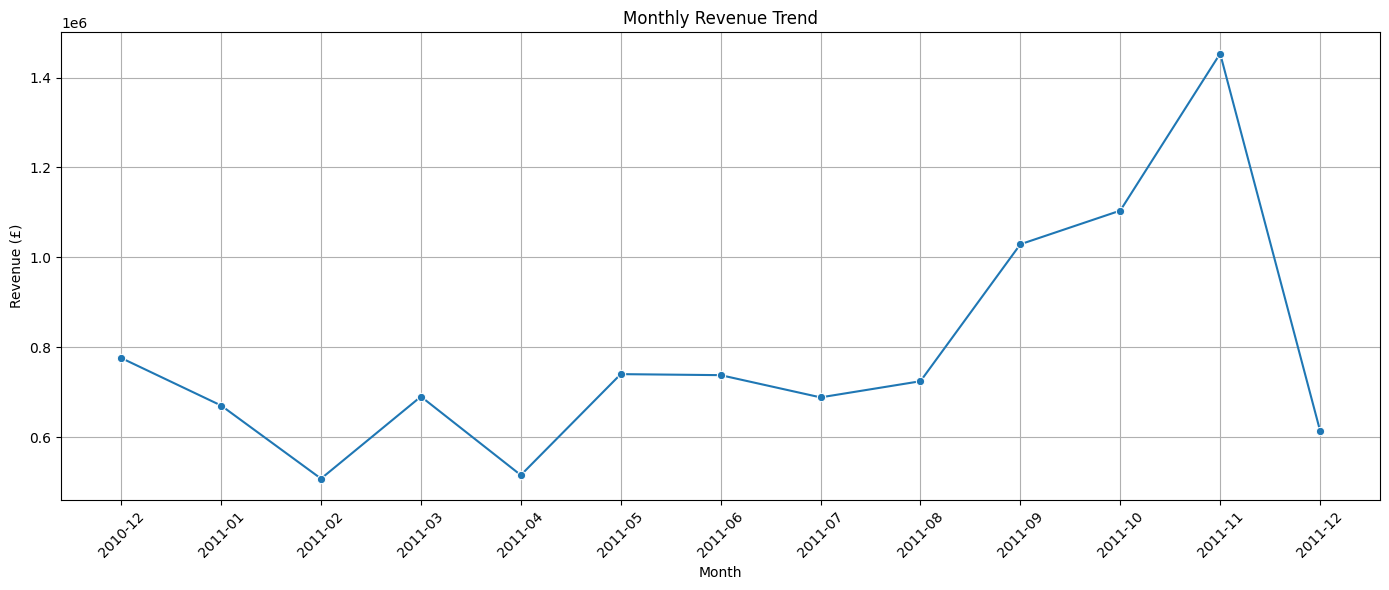

In [ ]:
# Extract year and month from InvoiceDate

df_product_sales['InvoiceMonth'] = (
    df_product_sales['InvoiceDate'].dt.to_period('M')
)

# Calculate monthly revenue
monthly_sales = (
    df_product_sales
    .groupby('InvoiceMonth')['TotalPrice']
    .sum()
    .reset_index()
)

monthly_sales['InvoiceMonth'] = (
    monthly_sales['InvoiceMonth'].astype(str)
)

print("MONTHLY SALES SUMMARY")
display(monthly_sales)

# Visualize monthly revenue
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x='InvoiceMonth',
    y='TotalPrice',
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate total quantity sold for each product

top_products = (
    df_product_sales
    .groupby('Description')
    .agg(
        Total_Quantity=('Quantity', 'sum'),
        Total_Revenue=('TotalPrice', 'sum')
    )
    .sort_values(
        by='Total_Quantity',
        ascending=False
    )
    .head(10)
    .reset_index()
)

print("TOP 10 BEST-SELLING PRODUCTS")
display(top_products)

TOP 10 BEST-SELLING PRODUCTS


,Description,Total_Quantity,Total_Revenue
0,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
1,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
2,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01
3,JUMBO BAG RED RETROSPOT,48371,94159.81
4,WHITE HANGING HEART T-LIGHT HOLDER,37872,106236.72
5,POPCORN HOLDER,36749,34288.67
6,PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45
7,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62
8,RABBIT NIGHT LIGHT,30739,66870.03
9,MINI PAINT SET VINTAGE,26633,16937.82


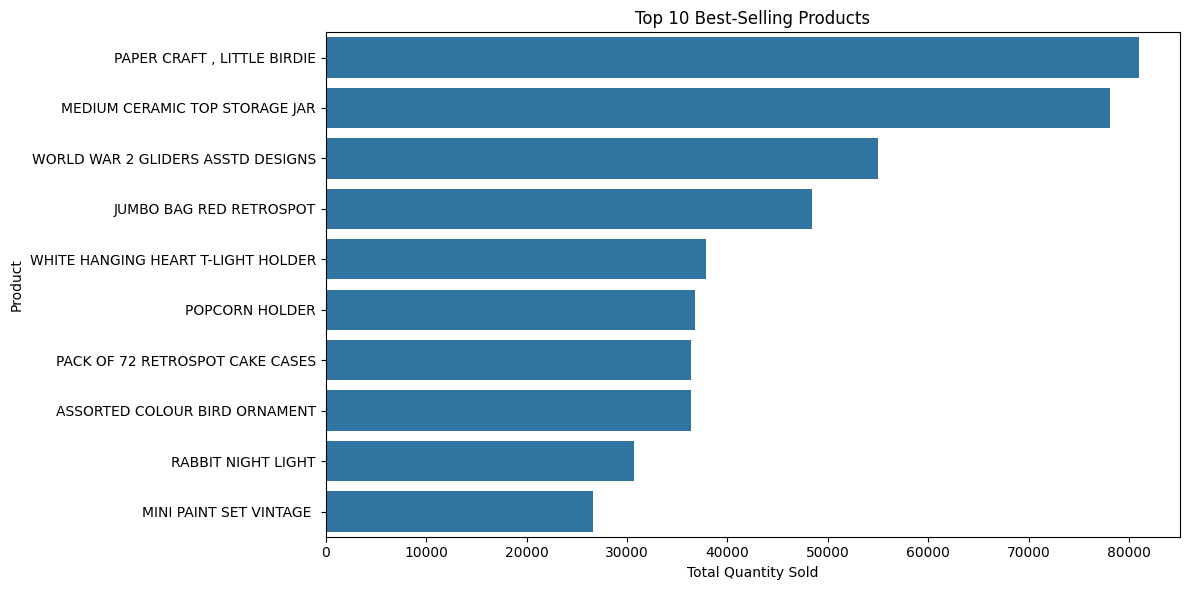

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products,
    x='Total_Quantity',
    y='Description'
)

plt.title('Top 10 Best-Selling Products')
plt.xlabel('Total Quantity Sold')
plt.ylabel('Product')

plt.tight_layout()
plt.show()

In [ ]:
# Calculate revenue by country

country_sales = (
    df_product_sales
    .groupby('Country')
    .agg(
        Total_Revenue=('TotalPrice', 'sum'),
        Total_Quantity=('Quantity', 'sum'),
        Total_Transactions=('InvoiceNo', 'nunique')
    )
    .sort_values(
        by='Total_Revenue',
        ascending=False
    )
    .reset_index()
)

print("COUNTRY-WISE SALES ANALYSIS")
display(country_sales.head(15))

COUNTRY-WISE SALES ANALYSIS


,Country,Total_Revenue,Total_Quantity,Total_Transactions
0,United Kingdom,8726832.534,4639191,17914
1,Netherlands,283889.340,200258,93
2,EIRE,276090.860,147002,284
3,Germany,205381.150,118032,443
4,France,184679.000,111229,383
5,Australia,138103.810,83890,56
6,Spain,55706.560,27724,88
7,Switzerland,53065.600,30515,50
8,Japan,37416.370,26016,19
9,Belgium,36927.340,22962,98


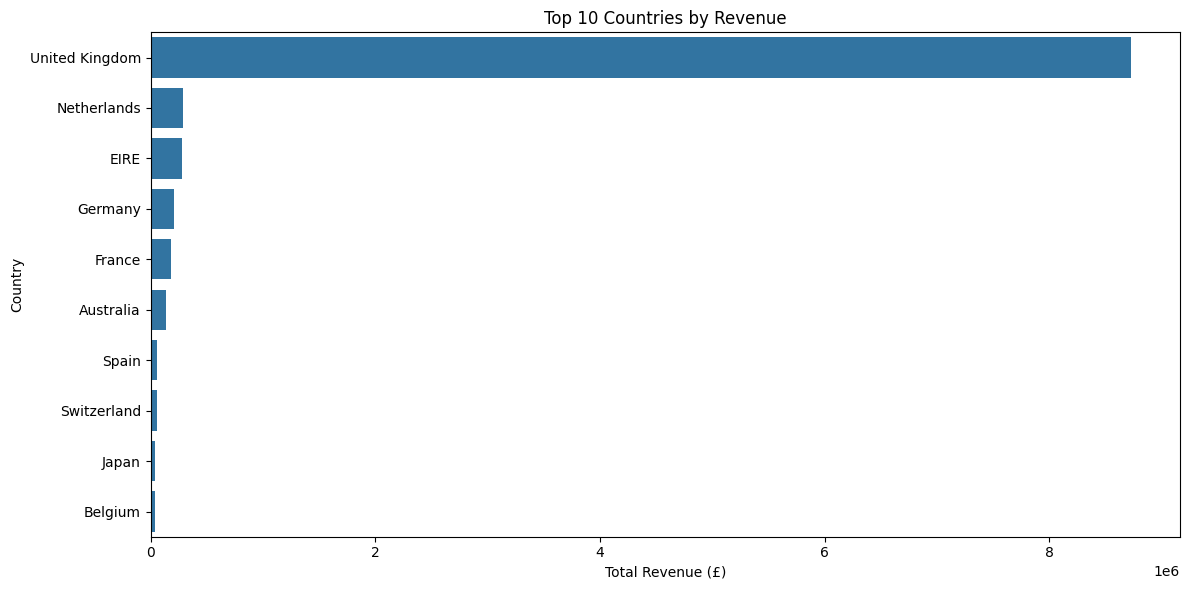

In [ ]:
top_countries = country_sales.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_countries,
    x='Total_Revenue',
    y='Country'
)

plt.title('Top 10 Countries by Revenue')
plt.xlabel('Total Revenue (£)')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

In [ ]:
# Create a separate dataset for customer-level analysis

df_rfm_transactions = df_product_sales[
    df_product_sales['CustomerID'].notna()
].copy()

# Ensure CustomerID has a consistent data type
df_rfm_transactions['CustomerID'] = (
    df_rfm_transactions['CustomerID'].astype(int)
)

# Check the prepared dataset

print("RFM TRANSACTION DATASET")
print("-----------------------")

print("Total product sales records:",
      len(df_product_sales))

print("Records with known CustomerID:",
      len(df_rfm_transactions))

print("Records excluded due to missing CustomerID:",
      len(df_product_sales) - len(df_rfm_transactions))

print("Unique customers:",
      df_rfm_transactions['CustomerID'].nunique())

print("Unique invoices:",
      df_rfm_transactions['InvoiceNo'].nunique())

print("\nMissing values:")
display(df_rfm_transactions.isnull().sum())

RFM TRANSACTION DATASET
-----------------------
Total product sales records: 522726
Records with known CustomerID: 391298
Records excluded due to missing CustomerID: 131428
Unique customers: 4335
Unique invoices: 18416

Missing values:


,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0
TotalPrice,0
InvoiceMonth,0


In [ ]:
# RFM Feature Engineering

# Set reference date as one day after the latest transaction
snapshot_date = (
    df_rfm_transactions['InvoiceDate'].max()
    + pd.Timedelta(days=1)
)

print("Reference Date:", snapshot_date)

# Calculate RFM metrics for each customer
rfm = (
    df_rfm_transactions
    .groupby('CustomerID')
    .agg(
        Recency=(
            'InvoiceDate',
            lambda x: (snapshot_date - x.max()).days
        ),
        Frequency=(
            'InvoiceNo',
            'nunique'
        ),
        Monetary=(
            'TotalPrice',
            'sum'
        )
    )
    .reset_index()
)

print("\nRFM DATASET")
print("----------------")

print("Total customers:", len(rfm))

display(rfm.head(10))

Reference Date: 2011-12-10 12:50:00

RFM DATASET
----------------
Total customers: 4335


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1437.24
3,12349,19,1,1457.55
4,12350,310,1,294.40
5,12352,36,7,1385.74
6,12353,204,1,89.00
7,12354,232,1,1079.40
8,12355,214,1,459.40
9,12356,23,3,2487.43


In [ ]:
# Statistical summary of RFM features

print("RFM STATISTICAL SUMMARY")
display(
    rfm[['Recency', 'Frequency', 'Monetary']].describe()
)

# Calculate skewness
print("\nRFM SKEWNESS")

display(
    rfm[['Recency', 'Frequency', 'Monetary']]
    .skew()
    .to_frame(name='Skewness')
)

# Check for invalid values
print("\nINVALID VALUE CHECK")

print("Recency <= 0:", (rfm['Recency'] <= 0).sum())
print("Frequency <= 0:", (rfm['Frequency'] <= 0).sum())
print("Monetary <= 0:", (rfm['Monetary'] <= 0).sum())

RFM STATISTICAL SUMMARY


,Recency,Frequency,Monetary
count,4335.000000,4335.000000,4335.000000
mean,92.708651,4.248212,2017.088499
std,100.206617,7.646024,8919.392095
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,304.250000
50%,51.000000,2.000000,663.610000
75%,143.000000,5.000000,1631.475000
max,374.000000,206.000000,279138.020000



RFM SKEWNESS


,Skewness
Recency,1.243824
Frequency,11.969891
Monetary,19.553846



INVALID VALUE CHECK
Recency <= 0: 0
Frequency <= 0: 0
Monetary <= 0: 0


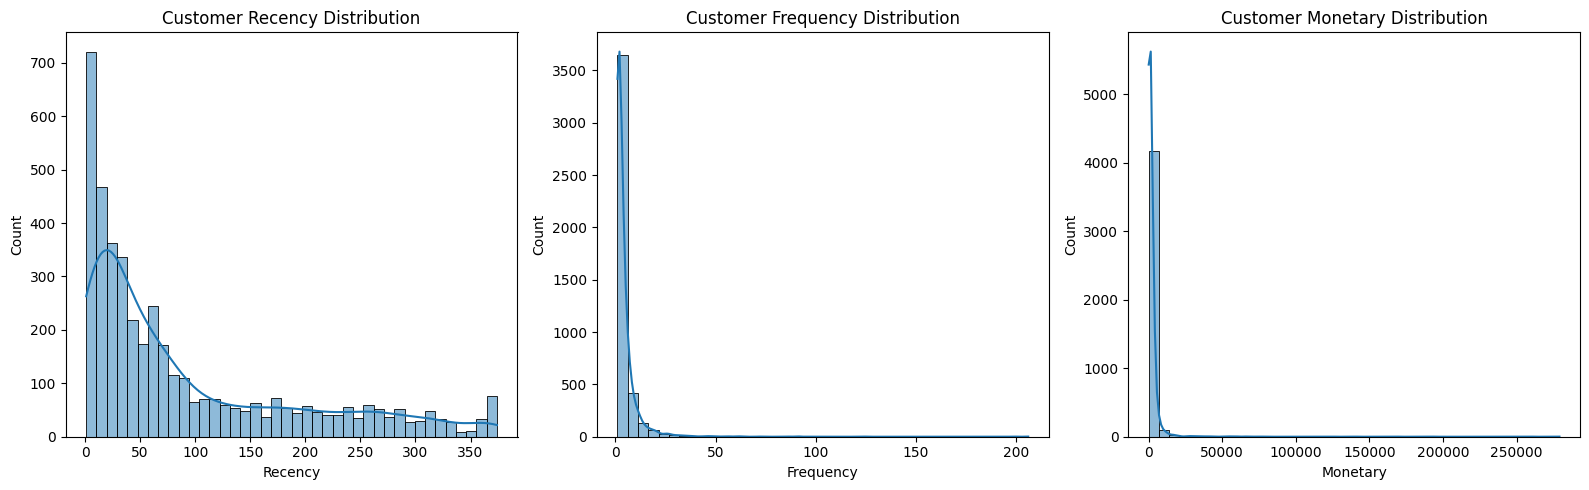

In [ ]:
# Visualize RFM feature distributions

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.histplot(rfm['Recency'], bins=40, kde=True, ax=axes[0])
axes[0].set_title('Customer Recency Distribution')

sns.histplot(rfm['Frequency'], bins=40, kde=True, ax=axes[1])
axes[1].set_title('Customer Frequency Distribution')

sns.histplot(rfm['Monetary'], bins=40, kde=True, ax=axes[2])
axes[2].set_title('Customer Monetary Distribution')

plt.tight_layout()
plt.show()

In [ ]:
# Identify customers with the highest monetary values

print("TOP 15 CUSTOMERS BY SPENDING")

display(
    rfm.nlargest(15, 'Monetary')[
        ['CustomerID', 'Recency', 'Frequency', 'Monetary']
    ]
)

print("\nTOP 15 CUSTOMERS BY FREQUENCY")

display(
    rfm.nlargest(15, 'Frequency')[
        ['CustomerID', 'Recency', 'Frequency', 'Monetary']
    ]
)

TOP 15 CUSTOMERS BY SPENDING


,CustomerID,Recency,Frequency,Monetary
1689,14646,2,72,279138.02
4198,18102,1,60,259657.30
3726,17450,8,46,194390.79
3007,16446,1,2,168472.50
1879,14911,1,199,140336.83
55,12415,24,20,124564.53
1333,14156,10,55,117210.08
3769,17511,3,31,91062.38
0,12346,326,1,77183.60
2701,16029,39,62,72708.09



TOP 15 CUSTOMERS BY FREQUENCY


,CustomerID,Recency,Frequency,Monetary
326,12748,1,206,31650.78
1879,14911,1,199,140336.83
4008,17841,2,124,40495.99
562,13089,3,97,58762.08
1661,14606,1,91,11941.15
2176,15311,1,91,60632.75
481,12971,4,86,11189.91
1689,14646,2,72,279138.02
795,13408,2,62,28117.04
2701,16029,39,62,72708.09


In [ ]:
# Create a separate copy of the RFM dataset

rfm_transformed = rfm.copy()

# Apply log1p transformation

rfm_transformed['Log_Recency'] = np.log1p(
    rfm_transformed['Recency']
)

rfm_transformed['Log_Frequency'] = np.log1p(
    rfm_transformed['Frequency']
)

rfm_transformed['Log_Monetary'] = np.log1p(
    rfm_transformed['Monetary']
)

# Compare skewness before and after transformation

rfm_skewness = pd.DataFrame({
    'Feature': ['Recency', 'Frequency', 'Monetary'],

    'Before Transformation': [
        rfm['Recency'].skew(),
        rfm['Frequency'].skew(),
        rfm['Monetary'].skew()
    ],

    'After Transformation': [
        rfm_transformed['Log_Recency'].skew(),
        rfm_transformed['Log_Frequency'].skew(),
        rfm_transformed['Log_Monetary'].skew()
    ]
})

print("RFM SKEWNESS COMPARISON")

display(rfm_skewness.round(3))

RFM SKEWNESS COMPARISON


,Feature,Before Transformation,After Transformation
0,Recency,1.244,-0.379
1,Frequency,11.970,1.214
2,Monetary,19.554,0.395


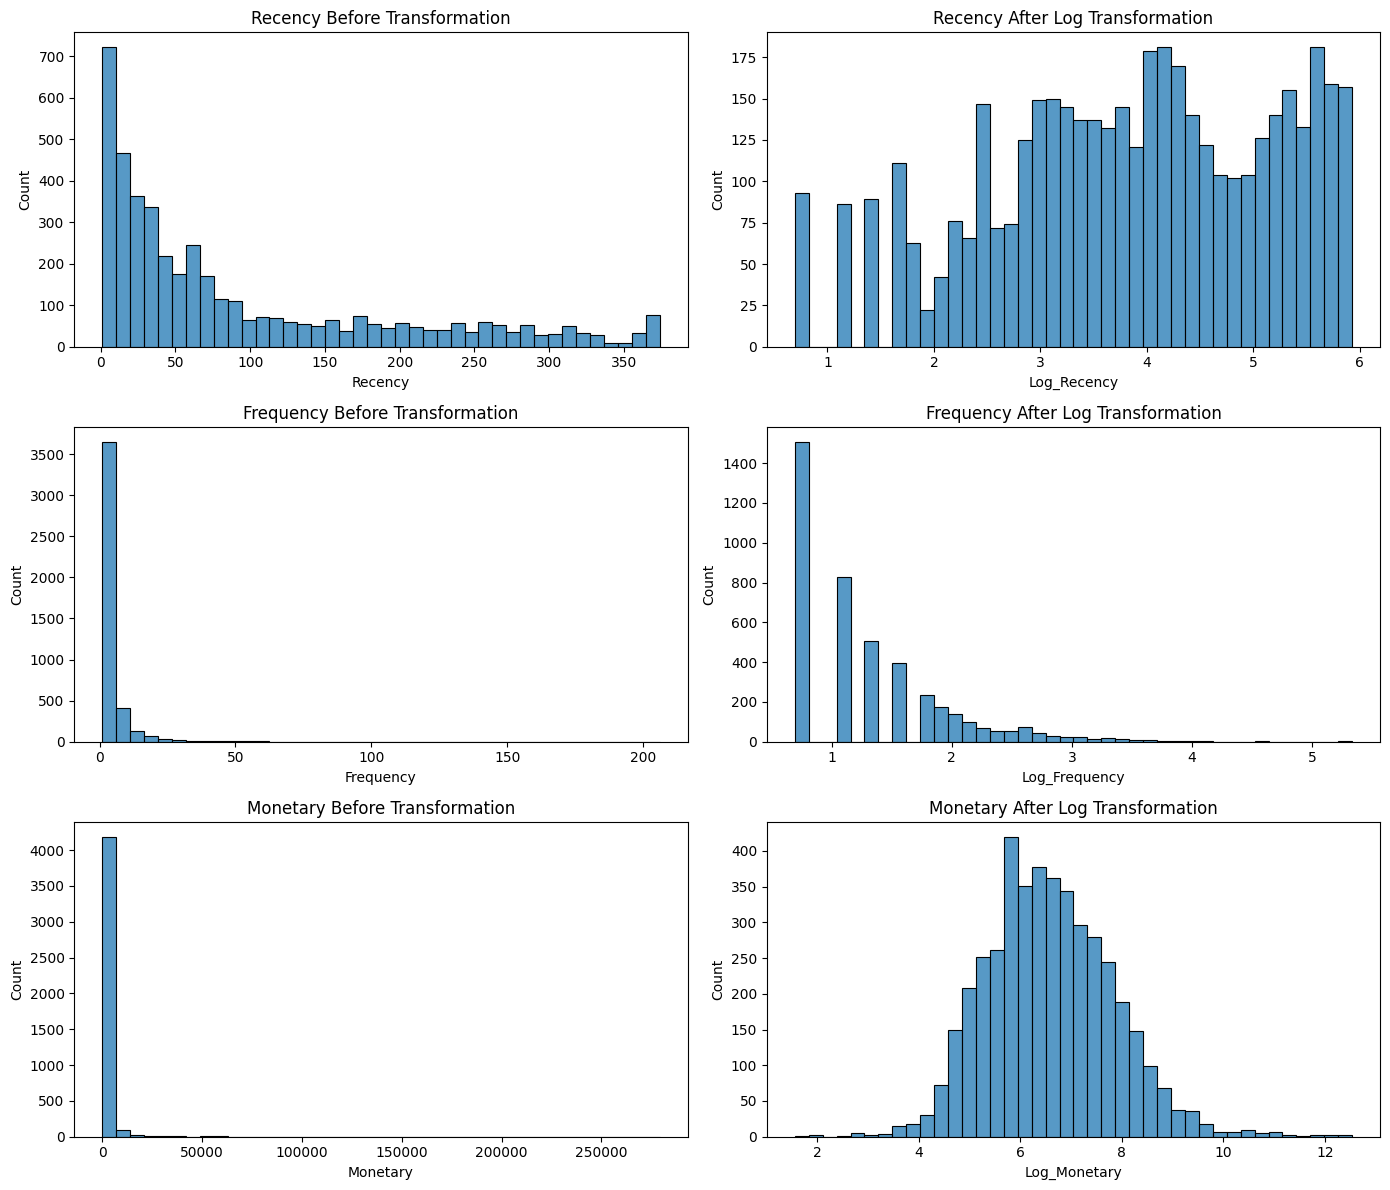

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

features = [
    ('Recency', 'Log_Recency'),
    ('Frequency', 'Log_Frequency'),
    ('Monetary', 'Log_Monetary')
]

for i, (original, transformed) in enumerate(features):

    sns.histplot(
        rfm_transformed[original],
        bins=40,
        ax=axes[i, 0]
    )

    axes[i, 0].set_title(f'{original} Before Transformation')

    sns.histplot(
        rfm_transformed[transformed],
        bins=40,
        ax=axes[i, 1]
    )

    axes[i, 1].set_title(f'{original} After Log Transformation')

plt.tight_layout()
plt.show()

In [ ]:
# STANDARDIZATION OF RFM FEATURES

from sklearn.preprocessing import StandardScaler

# Select transformed RFM features
rfm_features = [
    'Log_Recency',
    'Log_Frequency',
    'Log_Monetary'
]

# Initialize StandardScaler
scaler = StandardScaler()

# Fit and transform the features
rfm_scaled = rfm_transformed.copy()

scaled_values = scaler.fit_transform(
    rfm_scaled[rfm_features]
)

# Store standardized values
rfm_scaled[
    ['Scaled_Recency', 'Scaled_Frequency', 'Scaled_Monetary']
] = scaled_values

print("STANDARDIZED RFM DATASET")
print("------------------------")

display(
    rfm_scaled[
        [
            'CustomerID',
            'Scaled_Recency',
            'Scaled_Frequency',
            'Scaled_Monetary'
        ]
    ].head(10)
)

# Verify standardization
print("\nSTANDARDIZATION VERIFICATION")

display(
    rfm_scaled[
        [
            'Scaled_Recency',
            'Scaled_Frequency',
            'Scaled_Monetary'
        ]
    ].agg(['mean', 'std']).round(3)
)

STANDARDIZED RFM DATASET
------------------------


,CustomerID,Scaled_Recency,Scaled_Frequency,Scaled_Monetary
0,12346,1.460165,-0.951420,3.726618
1,12347,-2.037990,1.081712,1.428561
2,12348,0.372077,0.392407,0.554153
3,12349,-0.623381,-0.951420,0.565323
4,12350,1.422757,-0.951420,-0.706655
5,12352,-0.164662,1.081712,0.525107
6,12353,1.111979,-0.951420,-1.653366
7,12354,1.207444,-0.951420,0.326270
8,12355,1.147493,-0.951420,-0.353176
9,12356,-0.487431,0.065146,0.990845



STANDARDIZATION VERIFICATION


,Scaled_Recency,Scaled_Frequency,Scaled_Monetary
mean,0.0,-0.0,-0.0
std,1.0,1.0,1.0


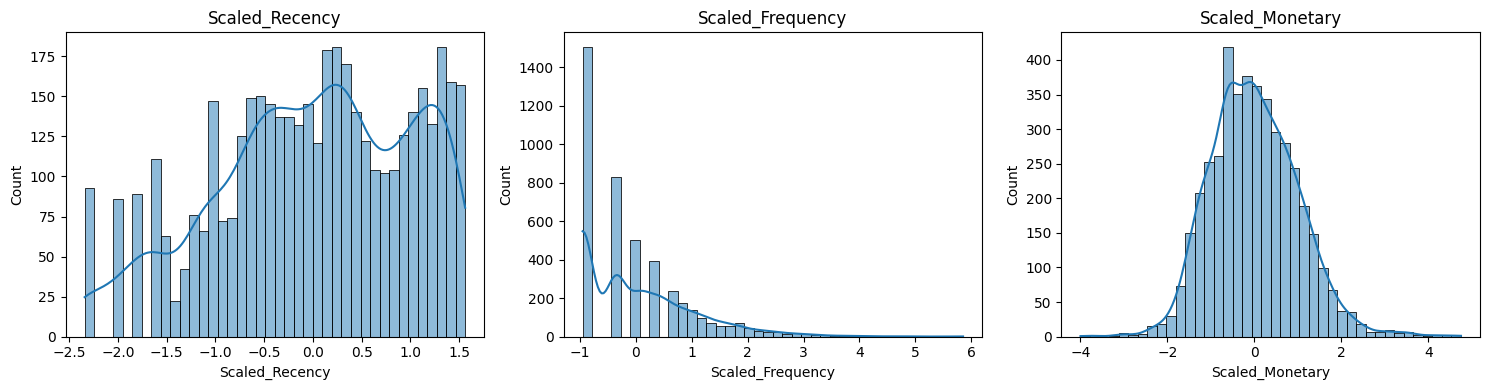

In [ ]:
# Visualize standardized RFM features

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

scaled_features = [
    'Scaled_Recency',
    'Scaled_Frequency',
    'Scaled_Monetary'
]

for i, feature in enumerate(scaled_features):

    sns.histplot(
        rfm_scaled[feature],
        bins=40,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(feature)

plt.tight_layout()
plt.show()

In [ ]:
# Prepare features for K-Means

from sklearn.cluster import KMeans

X = rfm_scaled[
    [
        'Scaled_Recency',
        'Scaled_Frequency',
        'Scaled_Monetary'
    ]
]

print("K-MEANS INPUT DATA")
print("------------------")
print("Shape:", X.shape)
print("\nMissing values:")
print(X.isnull().sum())

print("\nFirst 5 records:")
display(X.head())

K-MEANS INPUT DATA
------------------
Shape: (4335, 3)

Missing values:
Scaled_Recency      0
Scaled_Frequency    0
Scaled_Monetary     0
dtype: int64

First 5 records:


,Scaled_Recency,Scaled_Frequency,Scaled_Monetary
0,1.460165,-0.951420,3.726618
1,-2.037990,1.081712,1.428561
2,0.372077,0.392407,0.554153
3,-0.623381,-0.951420,0.565323
4,1.422757,-0.951420,-0.706655


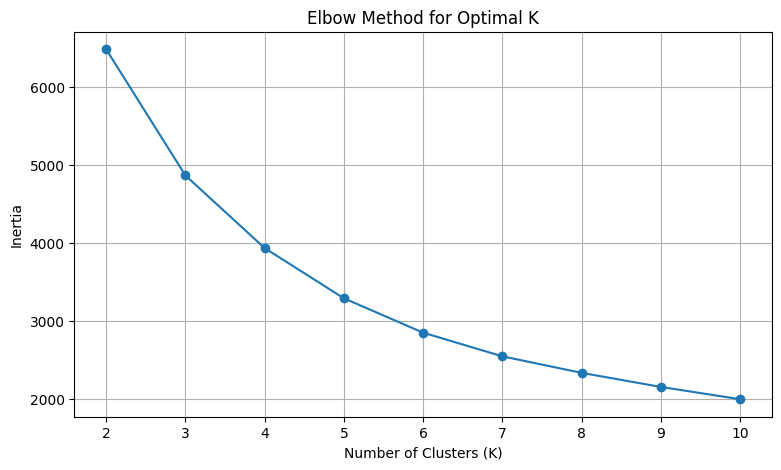

In [ ]:
# ELBOW METHOD

inertia_values = []

K = range(2, 11)

for k in K:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)

    inertia_values.append(kmeans.inertia_)

# Plot Elbow Curve

plt.figure(figsize=(9, 5))

plt.plot(
    K,
    inertia_values,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')

plt.xticks(K)
plt.grid(True)

plt.show()

In [ ]:
# SILHOUETTE SCORE ANALYSIS

from sklearn.metrics import silhouette_score

silhouette_values = []
inertia_comparison = []

# Test different cluster counts
K_values = range(2, 9)

for k in K_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    # Calculate silhouette score
    score = silhouette_score(X, labels)

    silhouette_values.append(score)
    inertia_comparison.append(model.inertia_)

    print(f"K = {k} | Silhouette Score = {score:.4f}")


# Create comparison table
cluster_evaluation = pd.DataFrame({
    'Number of Clusters': list(K_values),
    'Inertia': inertia_comparison,
    'Silhouette Score': silhouette_values
})

print("\nCLUSTER EVALUATION SUMMARY")

display(cluster_evaluation.round(4))

K = 2 | Silhouette Score = 0.4329
K = 3 | Silhouette Score = 0.3375
K = 4 | Silhouette Score = 0.3367
K = 5 | Silhouette Score = 0.3163
K = 6 | Silhouette Score = 0.3134
K = 7 | Silhouette Score = 0.3091
K = 8 | Silhouette Score = 0.2973

CLUSTER EVALUATION SUMMARY


,Number of Clusters,Inertia,Silhouette Score
0,2,6479.7699,0.4329
1,3,4864.7870,0.3375
2,4,3934.8997,0.3367
3,5,3291.8455,0.3163
4,6,2851.9193,0.3134
5,7,2549.0261,0.3091
6,8,2337.6151,0.2973


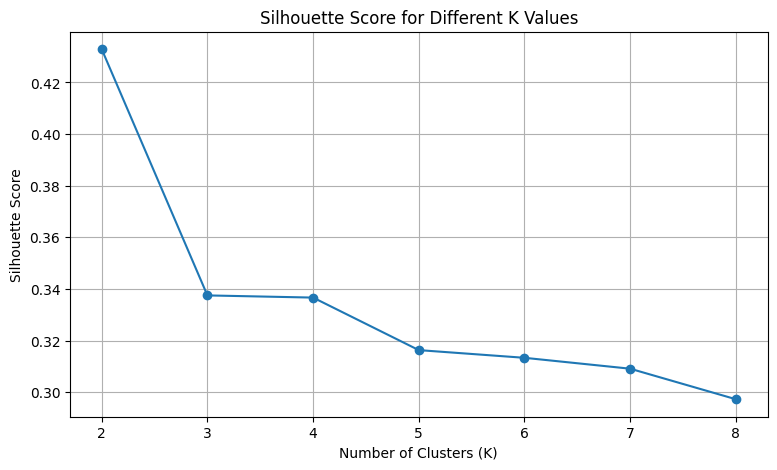

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    list(K_values),
    silhouette_values,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')

plt.title('Silhouette Score for Different K Values')

plt.xticks(list(K_values))
plt.grid(True)

plt.show()

In [ ]:
# FINAL K-MEANS MODEL

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Initialize K-Means with optimal K = 2
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Train model and predict cluster labels
cluster_labels = final_kmeans.fit_predict(X)

# Add cluster labels to customer dataset
rfm_final = rfm_scaled.copy()

rfm_final['Cluster'] = cluster_labels

# Calculate final silhouette score
final_silhouette = silhouette_score(X, cluster_labels)

print("FINAL K-MEANS MODEL RESULTS")
print("---------------------------")

print("Number of clusters:", 2)
print("Total customers:", len(rfm_final))
print("Silhouette Score:", round(final_silhouette, 4))

print("\nCUSTOMER DISTRIBUTION")

display(
    rfm_final['Cluster']
    .value_counts()
    .sort_index()
    .to_frame(name='Number of Customers')
)

print("\nSAMPLE CLUSTER ASSIGNMENTS")

display(
    rfm_final[
        ['CustomerID', 'Recency', 'Frequency', 'Monetary', 'Cluster']
    ].head(15)
)

FINAL K-MEANS MODEL RESULTS
---------------------------
Number of clusters: 2
Total customers: 4335
Silhouette Score: 0.4329

CUSTOMER DISTRIBUTION


,Number of Customers
Cluster,
0,1664
1,2671



SAMPLE CLUSTER ASSIGNMENTS


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,77183.60,0
1,12347,2,7,4310.00,0
2,12348,75,4,1437.24,0
3,12349,19,1,1457.55,1
4,12350,310,1,294.40,1
5,12352,36,7,1385.74,0
6,12353,204,1,89.00,1
7,12354,232,1,1079.40,1
8,12355,214,1,459.40,1
9,12356,23,3,2487.43,0


In [ ]:
# CUSTOMER CLUSTER PROFILING

cluster_profile = (
    rfm_final
    .groupby('Cluster')
    .agg(
        Customer_Count=('CustomerID', 'count'),
        Average_Recency=('Recency', 'mean'),
        Average_Frequency=('Frequency', 'mean'),
        Average_Monetary=('Monetary', 'mean'),
        Median_Recency=('Recency', 'median'),
        Median_Frequency=('Frequency', 'median'),
        Median_Monetary=('Monetary', 'median')
    )
    .round(2)
)

# Calculate percentage of customers in each cluster
cluster_profile['Customer_Percentage'] = (
    cluster_profile['Customer_Count']
    / len(rfm_final) * 100
).round(2)

print("CUSTOMER CLUSTER PROFILE")
print("------------------------")

display(cluster_profile)

CUSTOMER CLUSTER PROFILE
------------------------


,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary,Median_Recency,Median_Frequency,Median_Monetary,Customer_Percentage
Cluster,,,,,,,,
0,1664,25.81,8.40,4463.33,16.0,6.0,2035.68,38.39
1,2671,134.39,1.66,493.11,96.0,1.0,357.77,61.61


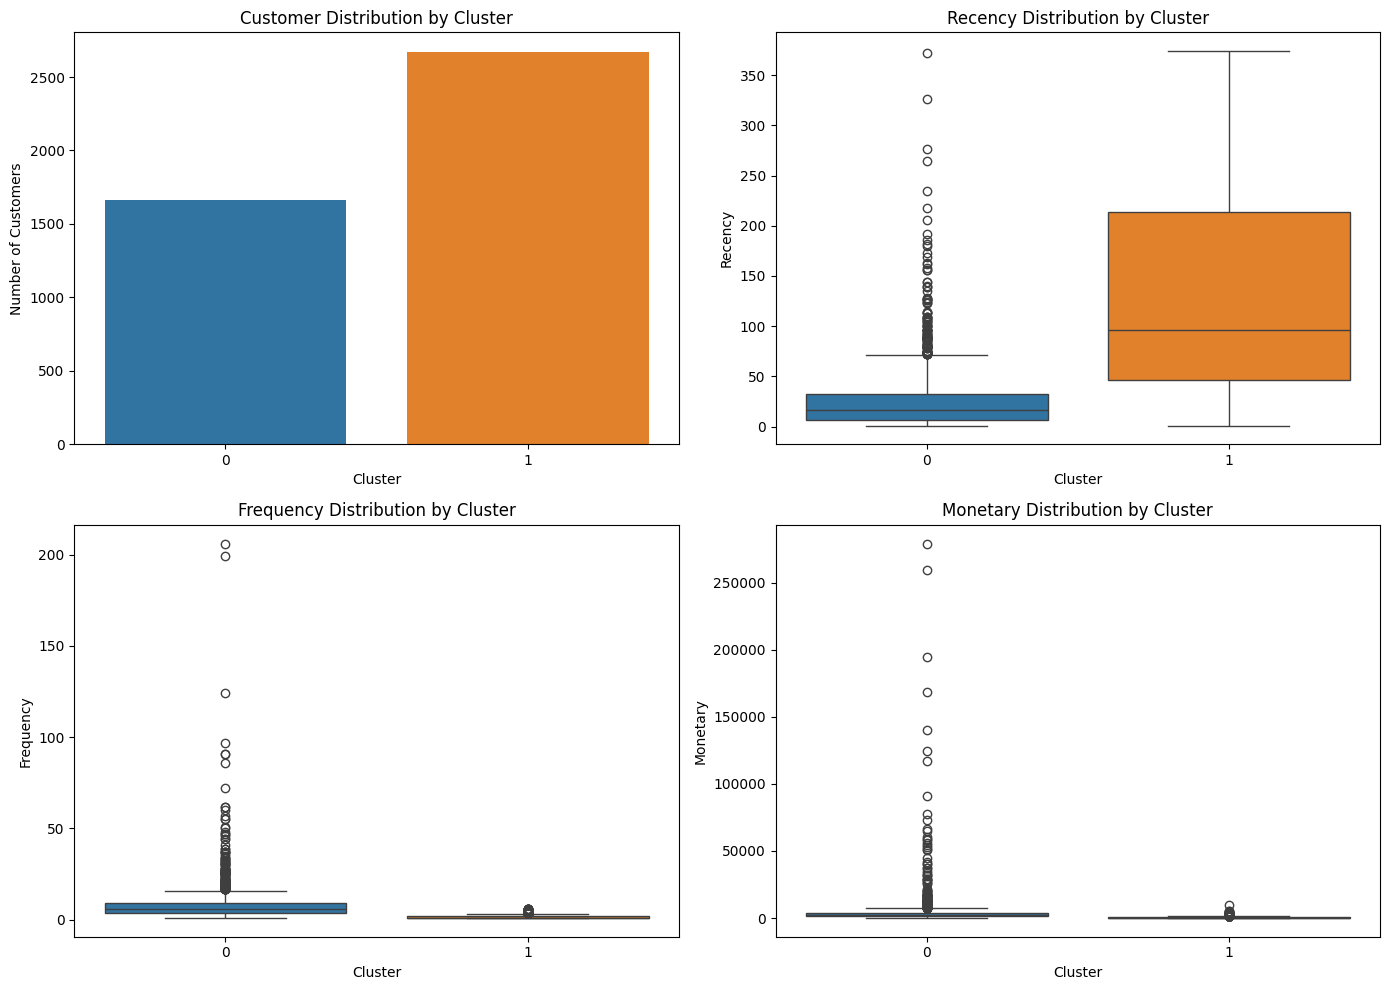

In [ ]:
# CUSTOMER CLUSTER VISUALIZATION

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Customer distribution
sns.countplot(
    data=rfm_final,
    x='Cluster',
    hue='Cluster',
    legend=False,
    ax=axes[0, 0]
)

axes[0, 0].set_title('Customer Distribution by Cluster')
axes[0, 0].set_xlabel('Cluster')
axes[0, 0].set_ylabel('Number of Customers')

# 2. Recency by cluster
sns.boxplot(
    data=rfm_final,
    x='Cluster',
    y='Recency',
    hue='Cluster',
    legend=False,
    ax=axes[0, 1]
)

axes[0, 1].set_title('Recency Distribution by Cluster')

# 3. Frequency by cluster
sns.boxplot(
    data=rfm_final,
    x='Cluster',
    y='Frequency',
    hue='Cluster',
    legend=False,
    ax=axes[1, 0]
)

axes[1, 0].set_title('Frequency Distribution by Cluster')

# 4. Monetary by cluster
sns.boxplot(
    data=rfm_final,
    x='Cluster',
    y='Monetary',
    hue='Cluster',
    legend=False,
    ax=axes[1, 1]
)

axes[1, 1].set_title('Monetary Distribution by Cluster')

plt.tight_layout()
plt.show()

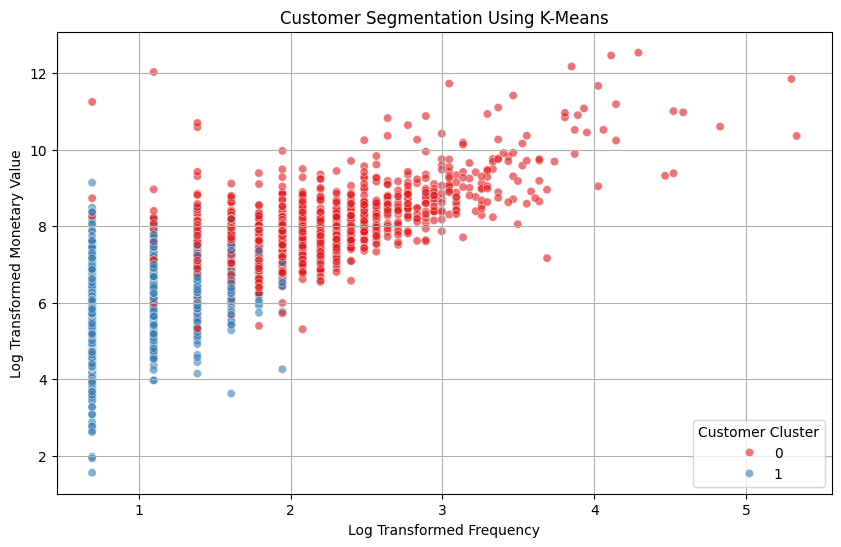

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm_final,
    x='Log_Frequency',
    y='Log_Monetary',
    hue='Cluster',
    palette='Set1',
    alpha=0.6
)

plt.title('Customer Segmentation Using K-Means')
plt.xlabel('Log Transformed Frequency')
plt.ylabel('Log Transformed Monetary Value')

plt.legend(title='Customer Cluster')
plt.grid(True)
plt.show()

In [ ]:
from google.colab import drive
import os
import shutil

# Connect Google Drive
drive.mount('/content/drive')

# Create project backup folder
backup_folder = '/content/drive/MyDrive/Retail_Customer_Segmentation'

os.makedirs(backup_folder, exist_ok=True)

print("Backup folder created successfully!")
print(backup_folder)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Backup folder created successfully!
/content/drive/MyDrive/Retail_Customer_Segmentation


In [ ]:
import os
import shutil

source_file = '/content/retail_data/Online Retail.xlsx'
destination_file = backup_folder + '/Online Retail.xlsx'

if os.path.exists(source_file):
    shutil.copy2(source_file, destination_file)
    print("Original dataset backed up successfully!")
else:
    print("Original dataset not found. Check the file location.")

Original dataset backed up successfully!


In [ ]:
import os

datasets_to_save = {
    'Cleaned_Transactions': 'df_cleaned',
    'Product_Sales': 'df_product_sales',
    'Regular_Sales': 'df_regular_sales',
    'RFM_Dataset': 'rfm_data',
    'RFM_Clustered': 'rfm_clustered'
}

for filename, variable_name in datasets_to_save.items():

    if variable_name in globals():
        dataframe = globals()[variable_name]

        dataframe.to_csv(
            f'{backup_folder}/{filename}.csv',
            index=False
        )

        print(f'{filename}.csv saved successfully!')

    else:
        print(f'{variable_name} not found. We will save it separately if needed.')

Cleaned_Transactions.csv saved successfully!
Product_Sales.csv saved successfully!
Regular_Sales.csv saved successfully!
rfm_data not found. We will save it separately if needed.
rfm_clustered not found. We will save it separately if needed.


In [ ]:
print("FILES IN GOOGLE DRIVE BACKUP FOLDER")
print("-----------------------------------")

for filename in os.listdir(backup_folder):
    filepath = os.path.join(backup_folder, filename)

    size_mb = os.path.getsize(filepath) / (1024 * 1024)

    print(f"{filename} - {size_mb:.2f} MB")

FILES IN GOOGLE DRIVE BACKUP FOLDER
-----------------------------------
Online Retail.xlsx - 22.62 MB
Cleaned_Transactions.csv - 45.38 MB
Product_Sales.csv - 51.85 MB
Regular_Sales.csv - 48.01 MB


In [ ]:
print("AVAILABLE RFM AND CLUSTER VARIABLES")
print("-----------------------------------")

for name, value in globals().items():
    if not name.startswith('_'):
        if isinstance(value, pd.DataFrame):
            if any(word in name.lower() for word in ['rfm', 'cluster', 'segment']):
                print(name, value.shape)

AVAILABLE RFM AND CLUSTER VARIABLES
-----------------------------------
df_rfm_transactions (391298, 10)
rfm (4335, 4)
rfm_transformed (4335, 7)
rfm_skewness (3, 3)
rfm_scaled (4335, 10)
cluster_evaluation (7, 3)
rfm_final (4335, 11)
cluster_profile (2, 8)


In [ ]:
rfm_datasets = {
    'RFM_Transactions': df_rfm_transactions,
    'RFM_Dataset': rfm,
    'RFM_Transformed': rfm_transformed,
    'RFM_Skewness_Comparison': rfm_skewness,
    'RFM_Standardized': rfm_scaled,
    'Cluster_Evaluation': cluster_evaluation,
    'Final_RFM_Clustered': rfm_final,
    'Customer_Cluster_Profile': cluster_profile
}

for filename, dataframe in rfm_datasets.items():

    filepath = f'{backup_folder}/{filename}.csv'

    dataframe.to_csv(filepath, index=False)

    print(f'{filename}.csv saved successfully! | Shape: {dataframe.shape}')

RFM_Transactions.csv saved successfully! | Shape: (391298, 10)
RFM_Dataset.csv saved successfully! | Shape: (4335, 4)
RFM_Transformed.csv saved successfully! | Shape: (4335, 7)
RFM_Skewness_Comparison.csv saved successfully! | Shape: (3, 3)
RFM_Standardized.csv saved successfully! | Shape: (4335, 10)
Cluster_Evaluation.csv saved successfully! | Shape: (7, 3)
Final_RFM_Clustered.csv saved successfully! | Shape: (4335, 11)
Customer_Cluster_Profile.csv saved successfully! | Shape: (2, 8)


In [ ]:
print("FINAL GOOGLE DRIVE BACKUP")
print("=" * 50)

total_size = 0

for filename in sorted(os.listdir(backup_folder)):

    filepath = os.path.join(backup_folder, filename)
    size_mb = os.path.getsize(filepath) / (1024 * 1024)

    total_size += size_mb

    print(f"{filename:<40} {size_mb:>8.2f} MB")

print("=" * 50)
print(f"Total backup size: {total_size:.2f} MB")
print("Backup verification completed.")

FINAL GOOGLE DRIVE BACKUP
Cleaned_Transactions.csv                    45.38 MB
Cluster_Evaluation.csv                       0.00 MB
Customer_Cluster_Profile.csv                 0.00 MB
Final_RFM_Clustered.csv                      0.56 MB
Online Retail.xlsx                          22.62 MB
Product_Sales.csv                           51.85 MB
RFM_Dataset.csv                              0.08 MB
RFM_Skewness_Comparison.csv                  0.00 MB
RFM_Standardized.csv                         0.55 MB
RFM_Transactions.csv                        38.81 MB
RFM_Transformed.csv                          0.31 MB
Regular_Sales.csv                           48.01 MB
Total backup size: 208.17 MB
Backup verification completed.


In [ ]:
from google.colab import drive
import pandas as pd
import numpy as np
import os

# Connect Google Drive
drive.mount('/content/drive')

# Set backup folder
backup_folder = '/content/drive/MyDrive/Retail_Customer_Segmentation'

# Load original dataset
df_raw = pd.read_excel(
    f'{backup_folder}/Online Retail.xlsx'
)

# Load cleaned dataset
df_cleaned = pd.read_csv(
    f'{backup_folder}/Cleaned_Transactions.csv',
    parse_dates=['InvoiceDate']
)

# Load final clustering results
rfm_final = pd.read_csv(
    f'{backup_folder}/Final_RFM_Clustered.csv'
)

print("DATASETS RESTORED SUCCESSFULLY")
print("--------------------------------")
print("Original dataset:", df_raw.shape)
print("Cleaned dataset:", df_cleaned.shape)
print("Final RFM dataset:", rfm_final.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATASETS RESTORED SUCCESSFULLY
--------------------------------
Original dataset: (541909, 8)
Cleaned dataset: (536641, 8)
Final RFM dataset: (4335, 11)


In [ ]:
print("ORIGINAL DATASET")
display(df_raw.head())

print("\nCLEANED DATASET")
display(df_cleaned.head())

print("\nFINAL CUSTOMER SEGMENTATION")
display(rfm_final.head())

ORIGINAL DATASET


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



CLEANED DATASET


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



FINAL CUSTOMER SEGMENTATION


,CustomerID,Recency,Frequency,Monetary,Log_Recency,Log_Frequency,Log_Monetary,Scaled_Recency,Scaled_Frequency,Scaled_Monetary,Cluster
0,12346,326,1,77183.60,5.789960,0.693147,11.253955,1.460165,-0.951420,3.726618,0
1,12347,2,7,4310.00,1.098612,2.079442,8.368925,-2.037990,1.081712,1.428561,0
2,12348,75,4,1437.24,4.330733,1.609438,7.271175,0.372077,0.392407,0.554153,0
3,12349,19,1,1457.55,2.995732,0.693147,7.285198,-0.623381,-0.951420,0.565323,1
4,12350,310,1,294.40,5.739793,0.693147,5.688330,1.422757,-0.951420,-0.706655,1


In [ ]:
# Function to assess data quality
def assess_data_quality(data, dataset_name):

    return {
        'Dataset': dataset_name,
        'Total Records': len(data),
        'Total Columns': len(data.columns),
        'Missing Values': data.isnull().sum().sum(),
        'Duplicate Records': data.duplicated().sum(),
        'Missing Descriptions': data['Description'].isnull().sum(),
        'Missing CustomerIDs': data['CustomerID'].isnull().sum(),
        'Negative Quantities': (data['Quantity'] < 0).sum(),
        'Zero Quantities': (data['Quantity'] == 0).sum(),
        'Negative Unit Prices': (data['UnitPrice'] < 0).sum(),
        'Zero Unit Prices': (data['UnitPrice'] == 0).sum(),
        'Cancellation Records': (
            data['InvoiceNo'].astype(str).str.startswith('C')
        ).sum()
    }


# Assess original and cleaned datasets
quality_before = assess_data_quality(df_raw, 'Original Dataset')
quality_after = assess_data_quality(df_cleaned, 'Cleaned Dataset')

# Create comparison DataFrame
quality_comparison = pd.DataFrame([
    quality_before,
    quality_after
])

# Display results
print("BEFORE-AND-AFTER DATA QUALITY COMPARISON")
print("=" * 60)

display(quality_comparison.set_index('Dataset').T)

BEFORE-AND-AFTER DATA QUALITY COMPARISON


Dataset,Original Dataset,Cleaned Dataset
Total Records,541909,536641
Total Columns,8,8
Missing Values,136534,135458
Duplicate Records,5268,0
Missing Descriptions,1454,421
Missing CustomerIDs,135080,135037
Negative Quantities,10624,10587
Zero Quantities,0,0
Negative Unit Prices,2,2
Zero Unit Prices,2515,2510


In [ ]:
# Calculate duplicate removal
duplicates_removed = (
    quality_before['Duplicate Records']
    - quality_after['Duplicate Records']
)

# Calculate description recovery
descriptions_recovered = (
    quality_before['Missing Descriptions']
    - quality_after['Missing Descriptions']
)

description_recovery_rate = (
    descriptions_recovered /
    quality_before['Missing Descriptions']
) * 100

# Calculate record retention
records_removed = (
    quality_before['Total Records']
    - quality_after['Total Records']
)

record_retention_rate = (
    quality_after['Total Records'] /
    quality_before['Total Records']
) * 100

print("DATA CLEANING IMPACT")
print("=" * 45)

print("Duplicate records removed:", duplicates_removed)
print("Descriptions recovered:", descriptions_recovered)
print(f"Description recovery rate: {description_recovery_rate:.2f}%")
print("Total records removed:", records_removed)
print(f"Record retention rate: {record_retention_rate:.2f}%")
print("Remaining missing descriptions:",
      quality_after['Missing Descriptions'])
print("Remaining missing CustomerIDs:",
      quality_after['Missing CustomerIDs'])

DATA CLEANING IMPACT
Duplicate records removed: 5268
Descriptions recovered: 1033
Description recovery rate: 71.05%
Total records removed: 5268
Record retention rate: 99.03%
Remaining missing descriptions: 421
Remaining missing CustomerIDs: 135037


### Interpretation of Before-and-After Data Quality Assessment

The comparison demonstrates that the data-cleaning process improved the quality of the original Online Retail dataset while preserving most of its transactional information.

A total of 5,268 duplicate records were identified and removed, resulting in zero duplicate records in the cleaned dataset. Missing product descriptions were recovered using StockCode-based mapping wherever a unique and reliable description was available. This recovered 1,033 descriptions, achieving a recovery rate of 71.05%.

The remaining 421 missing descriptions were retained because reliable replacement values could not be established. Similarly, missing CustomerID values were preserved rather than artificially imputed, since CustomerID represents a unique customer identifier.

The cleaned dataset contains 536,641 records, corresponding to a retention rate of 99.03%. Negative quantities, zero-priced transactions and other special transaction records were retained for appropriate analysis instead of being automatically classified as errors.

Overall, the comparison demonstrates that the cleaning process reduced duplicate records and missing descriptions while maintaining the integrity of the original transactional data.

### Interpretation of Customer Segments

The K-Means clustering algorithm identified two distinct customer segments based on Recency, Frequency and Monetary (RFM) values.

**Cluster 0 – High-Value and Active Customers**

Cluster 0 contains 1,664 customers, representing 38.39% of the total customer base. These customers have an average recency of 25.81 days, an average purchase frequency of 8.40 transactions and an average monetary value of £4,463.33.

This segment generally represents recently active customers who purchase more frequently and contribute higher revenue. The business can focus on customer retention through loyalty programs, exclusive offers and personalized product recommendations.

**Cluster 1 – Low-Engagement and Occasional Customers**

Cluster 1 contains 2,671 customers, representing 61.61% of the total customer base. These customers have an average recency of 134.39 days, an average purchase frequency of 1.66 transactions and an average monetary value of £493.11.

This segment generally represents customers who purchase less frequently, have longer gaps between purchases and contribute lower revenue. The business can target these customers through re-engagement campaigns, personalized discounts and promotional offers to encourage repeat purchases.

**Overall Interpretation**

The clustering results reveal differences in customer purchasing behaviour. Cluster 0 represents the more valuable and active segment, while Cluster 1 represents customers with comparatively lower engagement.

These insights can help businesses develop targeted marketing strategies, improve customer retention and allocate promotional resources more effectively.

## Limitations of the Project

Although the project successfully performs data cleaning, preprocessing and customer segmentation, it has certain limitations:

1. **Missing Customer Information:** Approximately 25% of the original records have missing CustomerID values. These records cannot be used for customer-level RFM analysis.

2. **Historical Dataset:** The dataset contains retail transactions from December 2010 to December 2011. Therefore, the identified customer behaviour may not represent current purchasing trends.

3. **Unsupervised Learning:** K-Means does not use predefined customer categories. The resulting clusters are based on similarities in RFM features and require interpretation.

4. **Sensitivity to Outliers:** Extremely high purchase quantities and monetary values can influence cluster formation, even after log transformation and standardization.

5. **Limited Customer Features:** Segmentation is based only on Recency, Frequency and Monetary values. Other factors, such as customer demographics, product preferences and browsing behaviour, are not considered.

6. **Fixed Number of Clusters:** The final model uses two clusters based on the evaluated silhouette scores. Different datasets or feature combinations may produce different optimal cluster counts.

## Future Enhancements

The project can be extended in several ways to improve its analytical capabilities:

1. **Advanced Clustering Algorithms:** Algorithms such as DBSCAN, Agglomerative Clustering and Gaussian Mixture Models can be explored and compared with K-Means.

2. **Additional Customer Features:** Product preferences, purchase categories, average order value and customer location can be incorporated to develop more detailed customer profiles.

3. **Automated Data Cleaning:** An automated preprocessing pipeline can be developed to identify missing values, duplicates, inconsistent records and unusual transactions.

4. **Customer Churn Prediction:** Supervised machine-learning algorithms can be introduced to identify customers who are likely to stop purchasing.

5. **Interactive Dashboard:** A dashboard using Power BI, Tableau or Streamlit can display customer segments, sales trends and business insights interactively.

6. **Real-Time Customer Segmentation:** The system can be extended to process new transactions and periodically update customer segments based on changing purchasing behaviour.

## Conclusion

This project successfully demonstrated the application of data cleaning, preprocessing, exploratory data analysis and machine learning techniques on the UCI Online Retail dataset.

The original dataset contained 541,909 transaction records with missing values, duplicate entries, incomplete product descriptions and different types of transaction records. A systematic data-cleaning process was performed to improve data quality while preserving important transactional information. A total of 5,268 duplicate records were removed, and 1,033 missing product descriptions were recovered using StockCode-based mapping.

Logarithmic transformation and standardization were applied to reduce feature skewness and bring numerical attributes to comparable scales. Exploratory data analysis was then performed to understand monthly revenue trends, best-selling products and country-wise sales patterns.

RFM (Recency, Frequency and Monetary) analysis was used to extract meaningful customer-level features from the transaction data. These features were transformed and standardized before applying the K-Means clustering algorithm.

The final K-Means model identified two customer segments among 4,335 customers, achieving a silhouette score of 0.4329. The resulting segments revealed differences in purchasing frequency, recency and monetary contribution.

Overall, the project demonstrates how systematic data preprocessing and machine learning can convert raw transactional data into meaningful business insights. The identified customer segments can help businesses develop targeted marketing strategies, improve customer retention and make better data-driven decisions.

## RetailIQ model export

Run this section after running the original notebook through the final K-Means and cluster-profile cells. It saves the existing fitted scaler and K-Means model without fitting or changing either one. Files are written to an artifacts folder under the notebook's current working directory.

The export includes model/preprocessing metadata and the notebook's final customer assignments, cluster profiles, and evaluation results. It then reloads the saved artifacts and verifies the transformed features and predicted labels against the existing notebook results.

In [ ]:
# RETAILIQ_MODEL_EXPORT_SECTION
from pathlib import Path
import json
import platform
import sys

import joblib
import numpy as np
import sklearn
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# These are the already-fitted objects from the original notebook.
assert isinstance(scaler, StandardScaler), "Expected the fitted StandardScaler named scaler."
assert isinstance(final_kmeans, KMeans), "Expected the fitted K-Means model named final_kmeans."
assert final_kmeans.n_clusters == 2, "The fitted notebook model is expected to use two clusters."
assert list(scaler.feature_names_in_) == rfm_features
assert list(rfm_features) == ["Log_Recency", "Log_Frequency", "Log_Monetary"]
assert list(X.columns) == ["Scaled_Recency", "Scaled_Frequency", "Scaled_Monetary"]

# Validate the existing preprocessing and labels before exporting anything.
scaled_features = scaler.transform(rfm_transformed[rfm_features])
np.testing.assert_allclose(scaled_features, X.to_numpy())
np.testing.assert_array_equal(
    final_kmeans.predict(scaled_features),
    rfm_final["Cluster"].to_numpy()
)

artifact_dir = Path.cwd() / "artifacts"
artifact_dir.mkdir(parents=True, exist_ok=True)

scaler_path = artifact_dir / "standard_scaler.joblib"
kmeans_path = artifact_dir / "kmeans_model.joblib"
customers_path = artifact_dir / "final_customer_segmentation.csv"
profiles_path = artifact_dir / "cluster_profiles.csv"
metadata_path = artifact_dir / "metadata.json"

joblib.dump(scaler, scaler_path)
joblib.dump(final_kmeans, kmeans_path)
rfm_final.to_csv(customers_path, index=False)
cluster_profile.to_csv(profiles_path, index=True)

model_parameters = {
    key: (value.item() if isinstance(value, np.generic) else value)
    for key, value in final_kmeans.get_params(deep=False).items()
}
evaluation = [
    {
        "n_clusters": int(row["Number of Clusters"]),
        "inertia": float(row["Inertia"]),
        "silhouette_score": float(row["Silhouette Score"]),
    }
    for _, row in cluster_evaluation.iterrows()
]

metadata = {
    "artifact_format_version": 1,
    "model": {
        "class": "sklearn.cluster.KMeans",
        "source_variable": "final_kmeans",
        "parameters": model_parameters,
        "n_features_in": int(final_kmeans.n_features_in_),
        "feature_order": list(X.columns),
    },
    "scaler": {
        "class": "sklearn.preprocessing.StandardScaler",
        "source_variable": "scaler",
        "input_feature_order": list(rfm_features),
        "with_mean": bool(scaler.with_mean),
        "with_std": bool(scaler.with_std),
    },
    "preprocessing": {
        "rfm_features": ["Recency", "Frequency", "Monetary"],
        "transform": "numpy.log1p, applied separately to each RFM feature",
        "transformed_feature_order": list(rfm_features),
        "scaling": "fitted StandardScaler; transform order matches transformed_feature_order",
        "model_input_feature_order": list(X.columns),
        "frequency_definition": "distinct InvoiceNo count per CustomerID",
        "monetary_definition": "sum of Quantity * UnitPrice over filtered product-sales transactions",
        "recency_definition": "integer days from the customer's latest InvoiceDate to the reference date",
        "reference_date_rule": "maximum InvoiceDate in identified-customer product sales plus one day",
        "reference_date": pd.Timestamp(snapshot_date).isoformat(),
        "transaction_filters": [
            "remove exact duplicate rows",
            "exclude InvoiceNo values starting with C",
            "require Quantity > 0 and UnitPrice > 0",
            "exclude descriptions AMAZON FEE, POSTAGE, DOTCOM POSTAGE, Adjust bad debt, and Manual",
            "exclude rows without CustomerID from customer RFM and segmentation",
        ],
    },
    "training_data": {
        "rfm_transaction_rows": int(len(df_rfm_transactions)),
        "customers": int(len(rfm)),
        "clustered_customers": int(len(rfm_final)),
    },
    "evaluation": {
        "metric": "silhouette_score",
        "final_score": float(final_silhouette),
        "tested_cluster_counts": evaluation,
    },
    "files": {
        "scaler": scaler_path.name,
        "model": kmeans_path.name,
        "customer_segmentation": customers_path.name,
        "cluster_profiles": profiles_path.name,
    },
    "software": {
        "python": platform.python_version(),
        "scikit_learn": sklearn.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "joblib": joblib.__version__,
    },
}
metadata_path.write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")

# Reload every export and verify serialization preserves the notebook predictions.
required_files = [scaler_path, kmeans_path, customers_path, profiles_path, metadata_path]
assert all(path.is_file() and path.stat().st_size > 0 for path in required_files)
scaler_loaded = joblib.load(scaler_path)
kmeans_loaded = joblib.load(kmeans_path)
assert isinstance(scaler_loaded, StandardScaler)
assert isinstance(kmeans_loaded, KMeans)
np.testing.assert_allclose(
    scaler_loaded.transform(rfm_transformed[rfm_features]),
    scaled_features
)
np.testing.assert_array_equal(
    kmeans_loaded.predict(scaled_features),
    rfm_final["Cluster"].to_numpy()
)
assert pd.read_csv(customers_path).shape == rfm_final.shape
assert len(pd.read_csv(profiles_path)) == len(cluster_profile)
with metadata_path.open(encoding="utf-8") as metadata_file:
    assert json.load(metadata_file)["model"]["parameters"]["n_clusters"] == 2

print("Model export verified:")
for path in required_files:
    print(f"- {path.resolve()} ({path.stat().st_size:,} bytes)")